# Final contact study

The physical example is an ideal maintained bilateral contact in $\mathbb R^3$. Known resistance, the applied input and measured wrist-frame changes define recorded transformed input/output pairs
\[
u_t=P_{\mathcal X_t}v_t+e_t,\qquad \mathcal X_t\in\mathrm{Gr}(2,3),\quad e_t\sim\mathcal N(0,\sigma_t^2I_3).
\]
For matched isotropic resistance $D=dI$, the recorded requested velocity is $v_t=f_{\mathrm{eff},t}/d$. Let $n_t$ be the generating unit normal, so $P_{\mathcal X_t}=I_3-n_tn_t^T$; $n_t$ is withheld from the estimator. A noisy velocity is directly measured rather than inferred from differenced positions in the matched model. Surface positions and normals generate/score the experiment; the estimator receives only the recorded pairs and measured coordinate changes. Friction, contact loss, resistance errors and differenced-position measurements are separate mismatch experiments.

For a common-state block of $L$ observations with fixed variance, the increment is $(WV^T+VW^T-VV^T)/(2\sigma^2)$, without division by $L$. Known frame changes are aligned before a fixed-boundary block fit. Holding an output between completed blocks, exact aggregation and fitting one constant state over a moving block are different comparisons.

An admissible plane is represented by an unoriented normal line: $n$ and $-n$ describe the same plane. If the plane has parameter $A$, the normal has parameter $-A$. The actual and matched-isotropic normal laws share a mode and mean squared chordal distance. Their directional response risks can still differ. The anisotropy risk panel uses unit query directions; physical task panels use the declared requested speed and millimetre-per-second units. The constructed swapped-eigenvalue illustration is separately identified as an exact identity, not data-generated task performance.

The common $\overline P_t^+$, modal and $\overline P_t^{\mathrm{iso}}$ controls share the same posterior parameter and inputs. The regularized projector is $\rho P_{\widehat{\mathcal X}_t}+(1-\rho)(2/3)I_3$, with $\rho$ selected on independent validation episodes. This control uses the recorded inputs. GREAT is response-only and receives no recorded $v_t$, so its comparison cannot isolate Bayesian uncertainty. The plant trajectory is driven by a preassigned force program. Estimated responses and soft commands are scored counterfactually on this common stream; they are not fed back to regenerate a closed-loop trajectory. Soft command costs are expected penalties, not hard feasibility guarantees.

This notebook displays saved, source-verified evidence only, in theoretical-to-application order. All paper PDFs are title-free, seven inches wide, use actual LaTeX text and keep vector text/lines. Preview and raster layers use 300 dpi. Figures do not promise universal superiority, calibrated coverage under unmodelled motion, or exact EM ascent for approximate E-steps.


Every figure is now drawn by the full Matplotlib code in its own cell. Edit `DPI`, `FIGSIZE`, labels, styles, color scales or the PDF save command there. The setup cell exposes the shared `rcParams`. The one-line data loaders read the saved numerical arrays only. Notebook exports are separate from the published PDFs, so plotting experiments leave the scientific results intact.

In [1]:
from pathlib import Path
import os
import sys
ROOT = Path.cwd() if (Path.cwd()/'lib').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
EXAMPLE = 'contact'

# Use the optional local TeX installation when running in the cloud environment.
# On a machine with a system TeX installation this block has no effect.
LOCAL_TEX = Path('/workspace/.local/tex')
if (LOCAL_TEX / 'usr/bin/dvipng').exists():
    os.environ['PATH'] = str(LOCAL_TEX / 'usr/bin') + os.pathsep + os.environ['PATH']
    os.environ.setdefault('TEXMFHOME', str(LOCAL_TEX / 'usr/share/texmf'))

# Import data readers before setting the visible plotting defaults.
from lib.notebook_contact_data import load_contact_plot_data, contact_plot_input_hashes
from lib.notebook_inputs import verify_saved_inputs
from IPython import get_ipython
from IPython.display import display, Markdown
import numpy as np
import matplotlib.pyplot as plt

INPUT_HASHES = verify_saved_inputs(ROOT, EXAMPLE)
EDITABLE_OUTPUT = ROOT / 'results/notebook_exports/03_contact'
EDITABLE_OUTPUT.mkdir(parents=True, exist_ok=True)

# Shared defaults are editable here. Each figure cell also owns DPI and FIGSIZE.
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
    get_ipython().run_line_magic('config', "InlineBackend.figure_format = 'png'")
    get_ipython().run_line_magic('config', "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
plt.rcParams.update({
    'text.usetex': True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family': 'serif', 'font.size': 11,
    'axes.labelsize': 11, 'axes.titlesize': 11,
    'legend.fontsize': 10, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'lines.linewidth': 1.6, 'lines.markersize': 4,
    'figure.dpi': 300, 'savefig.dpi': 300, 'savefig.bbox': None,
    'axes.spines.top': False, 'axes.spines.right': False,
})
print('Verified', len(INPUT_HASHES), 'saved numerical inputs.')
print('Editable PDF output:', EDITABLE_OUTPUT)


Verified 104 saved numerical inputs.
Editable PDF output: /workspace/Bayesian-ST-test/results/notebook_exports/03_contact


## 1. Measurements and geometry

These checks distinguish the known-input and marginalized observation laws, finite-data curvature and expected information, exact aggregation and delayed actions. The sharper tracking envelope is evaluated only where its stated sufficient condition holds. Bound gaps, initialization and drift use generating quantities available for analysis, not online credible radii. Nonuniform priors, zero-signal data and concentrated inputs remain separate cohorts.

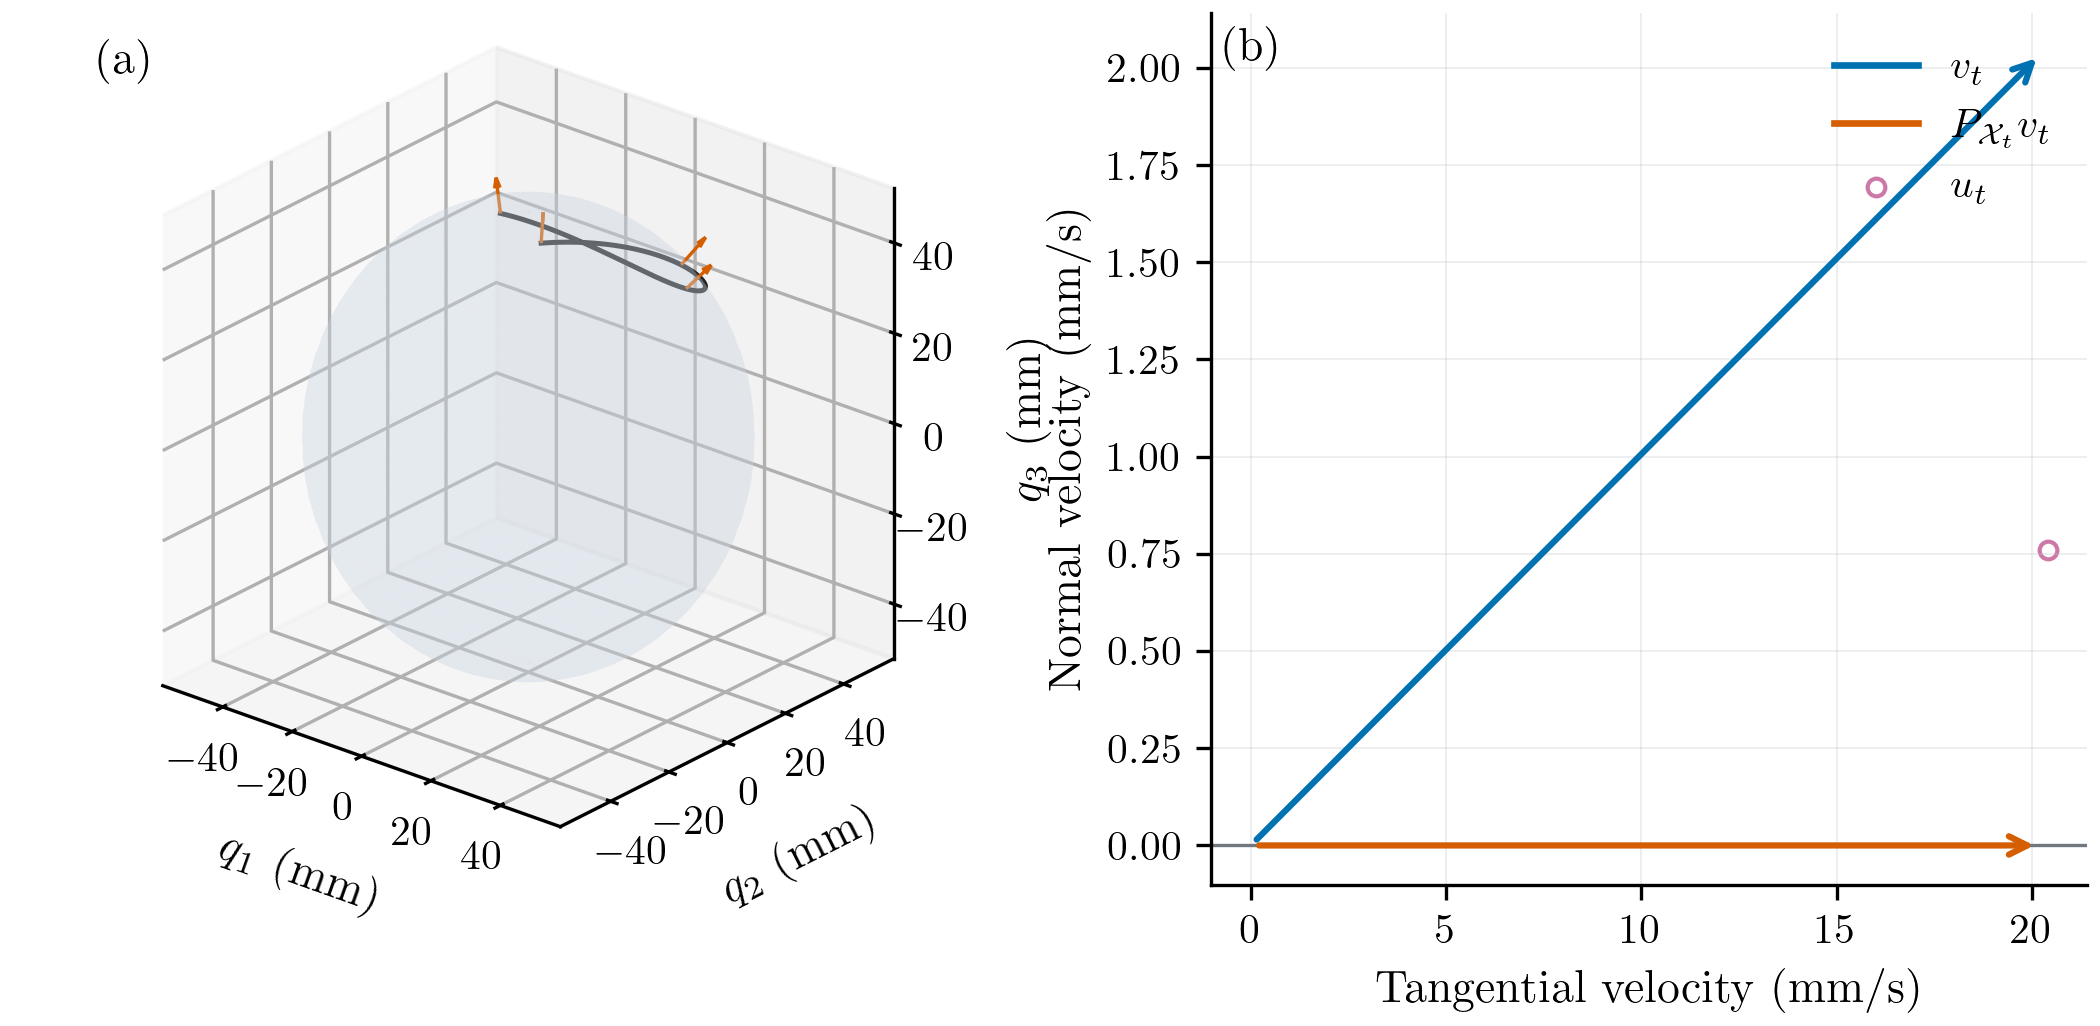

In [2]:
# Edit these controls, the labels below, or any Matplotlib call in this cell.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D

data = load_contact_plot_data(ROOT, 'setup', page=1)
DPI = 300
FIGSIZE = (7.0, 3.42)
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'setup_page1.pdf'

fig = plt.figure(figsize=FIGSIZE, dpi=DPI, layout="constrained")
grid = fig.add_gridspec(1, 2, width_ratios=(1.15, 1.))
ax = fig.add_subplot(grid[0, 0], projection="3d")

# The display mesh is geometric only; it is not an integration rule.
theta, phi = np.meshgrid(np.linspace(0., np.pi, 41), np.linspace(0., 2*np.pi, 81), indexing="ij")
mesh = np.stack([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)], axis=-1)
surface = ax.plot_surface(*(data["radius"]*1e3*mesh).transpose(2, 0, 1),
                          color="#CAD6E4", alpha=.22, linewidth=0., shade=False)
surface.set_rasterized(True)
positions, normals = data["positions"], data["normals"]
ax.plot(*(positions*1e3).T, color="#222222", linewidth=1.2)
for index in np.linspace(0, len(positions)-1, 4, dtype=int):
    ax.quiver(*(positions[index]*1e3), *normals[index], length=8., normalize=True,
              color="#D55E00", linewidth=.8)
ax.set_proj_type("ortho")
ax.view_init(elev=25., azim=-50.)
ax.set_box_aspect((1., 1., 1.))
ax.set_xlabel(r"$q_1$ (mm)", labelpad=-1)
ax.set_ylabel(r"$q_2$ (mm)", labelpad=-1)
ax.set_zlabel(r"$q_3$ (mm)", labelpad=-1)
ax.tick_params(labelsize=10., pad=-2)
ax.text2D(.02, .97, "(a)", transform=ax.transAxes, ha="left", va="top")

ax = fig.add_subplot(grid[0, 1])
V, U, clean = data["V"], data["U"], data["clean"]
normal = normals[0]/np.linalg.norm(normals[0])
tangent = V[0]-(V[0]@normal)*normal
tangent = tangent/np.linalg.norm(tangent)
for vector, color, label in [(V[0], "#0072B2", r"$v_t$"),
                              (clean[0], "#D55E00", r"$P_{\mathcal X_t}v_t$")]:
    x, y = 1e3*(vector@tangent), 1e3*(vector@normal)
    ax.annotate("", xy=(x, y), xytext=(0., 0.),
                arrowprops={"arrowstyle":"->", "color":color, "linewidth":1.5})
    ax.plot([], [], color=color, label=label)
ax.scatter(1e3*(U[0]@tangent), 1e3*(U[0]@normal), marker="o", s=18,
           facecolors="white", edgecolors="#CC79A7", label=r"$u_t$")
vectors = np.asarray([np.zeros(3), V[0], clean[0], U[0]])
ax.update_datalim(1e3*np.column_stack([vectors@tangent, vectors@normal]))
ax.autoscale_view()
ax.axhline(0., color="#70777D", linewidth=.8)
ax.set_xlabel("Tangential velocity (mm/s)")
ax.set_ylabel("Normal velocity (mm/s)")
ax.legend(frameon=False, fontsize=10.)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#BFC4C8", alpha=.30, linewidth=.45)
ax.text(.015, .985, "(b)", transform=ax.transAxes, ha="left", va="top")

# Custom notebook exports never overwrite the frozen paper catalogue.
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
plt.show()


## 2. Which normal rotations the observations distinguish

The contact likelihood conditions on the applied inputs. Its Fisher matrix $\mathcal F_{\mathrm{cond}}$ measures how strongly the distribution of observed velocities changes when the contact plane rotates. This is a property of the observation law; it is different from the curvature of a finite-data posterior.

Use the same 16 recorded inputs from the fixed concentrated-input example. At its generating plane, $n_0=e_3$ and $X_0=(e_1,e_2)$. The manuscript's local graph coordinates are $z=\operatorname{vec}(Z)=(z_1,z_2)^\top$, with
\[
n(Z)=\frac{n_0-X_0z}{\sqrt{1+\|z\|^2}}.
\]
Let $p_Z$ be the joint Gaussian velocity law at this rotated plane, with means $P_{\mathcal X(Z)}v_j$ and the same true measurement variance. For this fixture the exact divergence is
\[
D_{\mathrm{KL}}(p_0\|p_Z)
=\frac{z^\top\mathcal F_{\mathrm{cond}}z}{2(1+\|z\|^2)}.
\]
The left panel shows equal values of this divergence in the two native graph directions. The right panel converts each direction into the physical normal-rotation angle $\delta$: a $5^\circ$ rotation in the first direction and a $30^\circ$ rotation in the second both give a divergence of about $0.24$. The same input program therefore distinguishes these rotations very differently. Near the origin the expression reduces to the paper's $D_{\mathrm{KL}}=\tfrac12z^\top\mathcal F_{\mathrm{cond}}z+o(\|z\|^2)$.

These contours describe differences between likelihoods, rather than posterior credible regions. The generating plane and true variance are used for this theoretical analysis; neither the true normal nor extra observations are provided to the estimator. No new simulation, fitting or posterior calculation is introduced. [Curvature](../results/contact/posterior_curvature.pdf), [sharp tracking bound](../results/contact/tracking_bound.pdf), and [block updates](../results/contact/block_updates.pdf) retain the locality flags, sufficient conditions, initialization/noise/drift contributions and approximation checks.

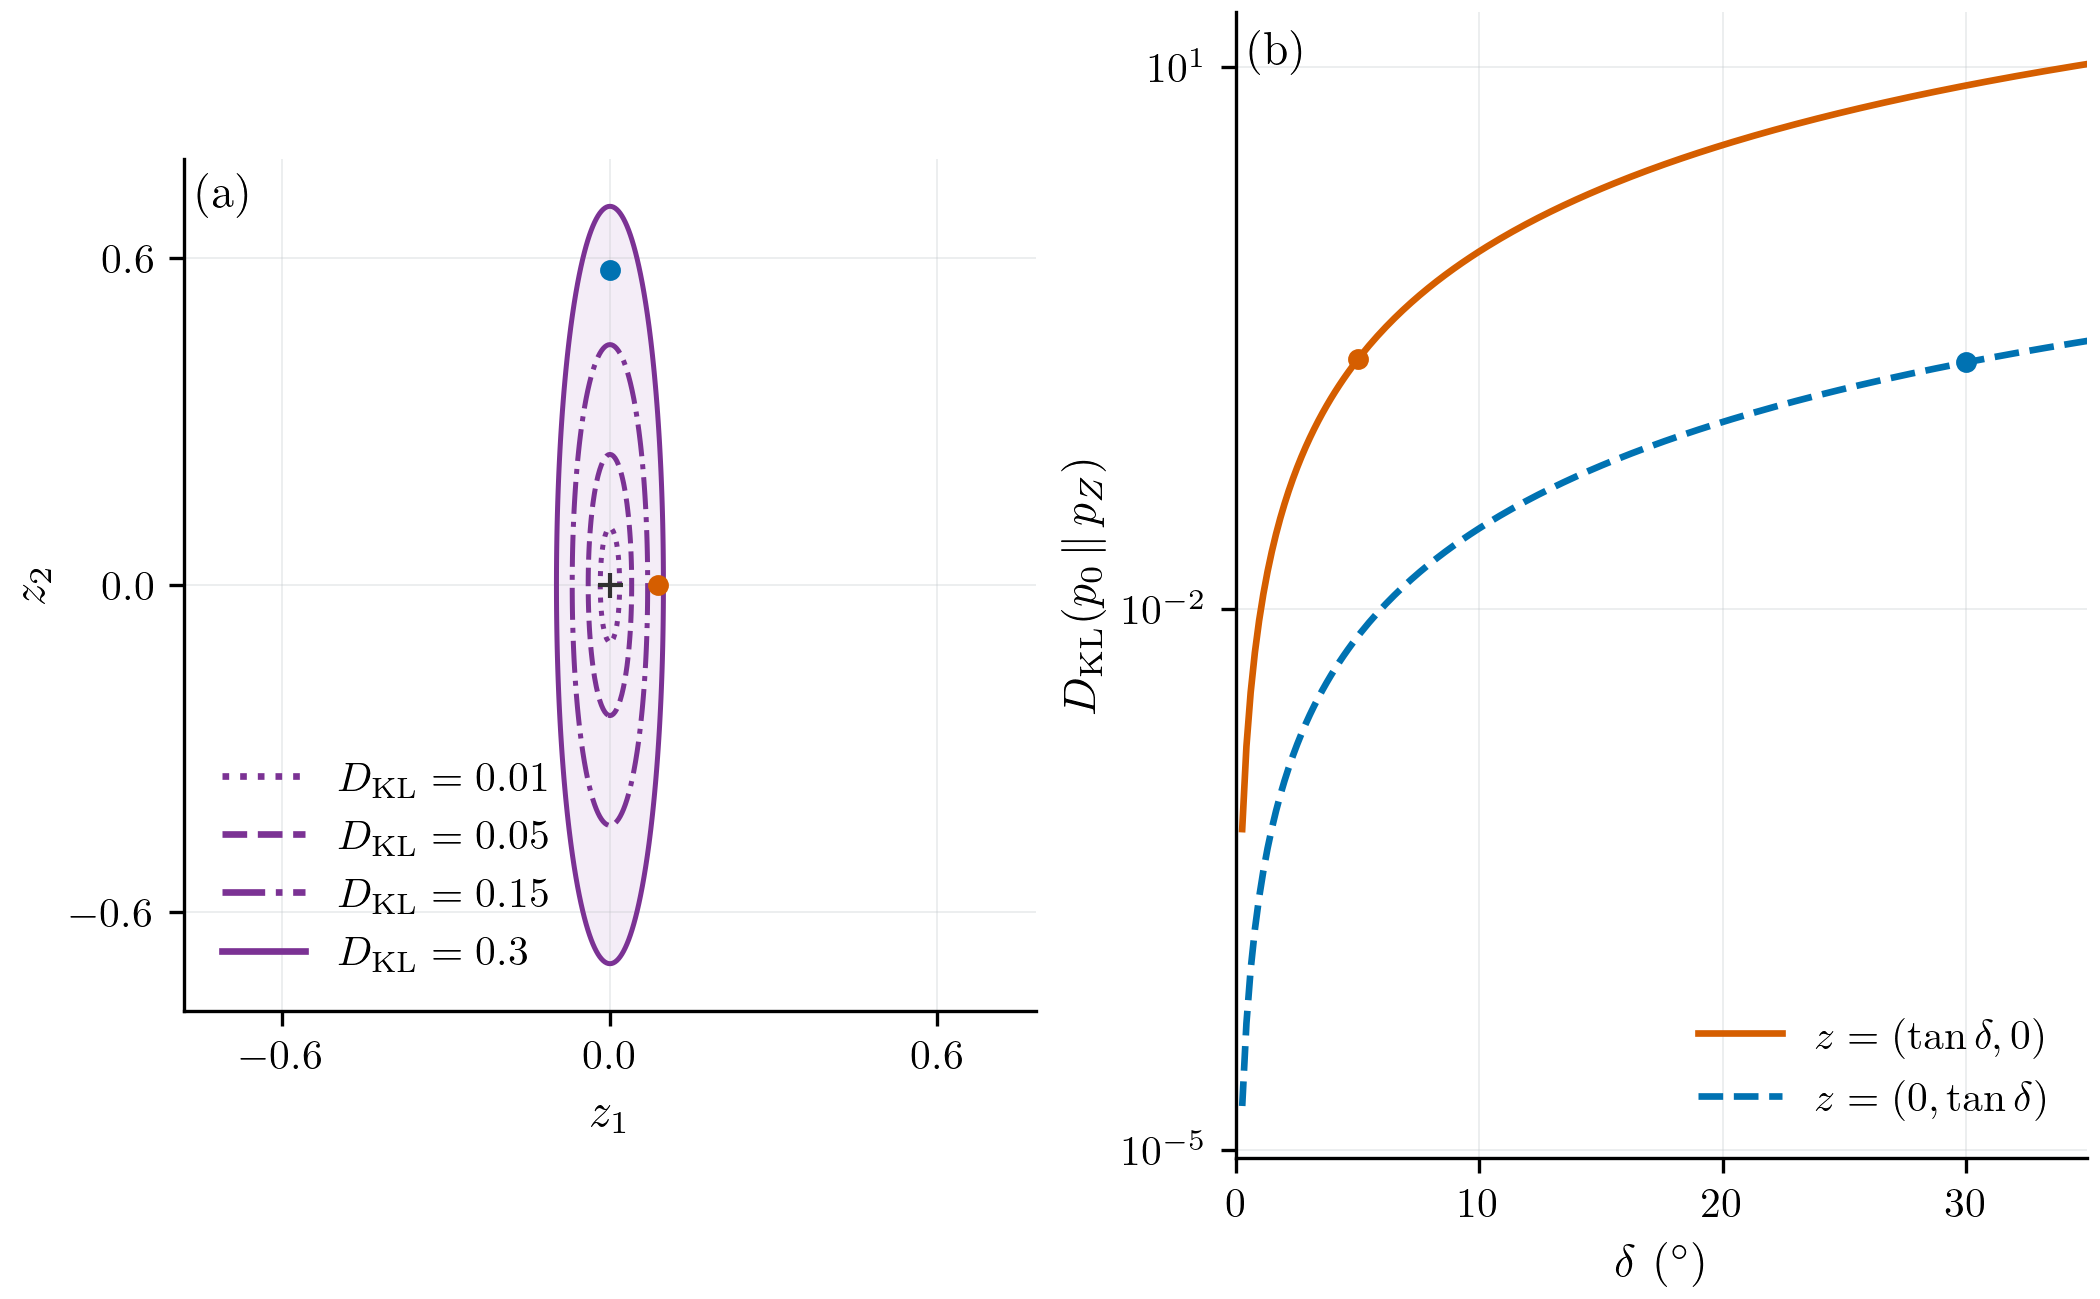

In [3]:
# Edit these controls, the labels below, or any Matplotlib call in this cell.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D

data = load_contact_plot_data(ROOT, 'information', page=1)
DPI = 300
FIGSIZE = (7.0, 4.332)
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'information_page1.pdf'

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, dpi=DPI, layout="constrained")
levels = [.01, .05, .15, .3]
contour_styles = [":", "--", "-.", "-"]
axes[0].contourf(data["z1"], data["z2"], data["kl"], levels=[0., levels[-1]], colors=["#F4EDF7"])
axes[0].contour(data["z1"], data["z2"], data["kl"], levels=levels,
                colors=["#7B3294"], linewidths=1.2, linestyles=contour_styles)
handles = [Line2D([], [], color="#7B3294", linestyle=style,
                  label=r"$D_{\mathrm{KL}}="+f"{level:g}"+r"$")
           for level, style in zip(levels, contour_styles)]
axes[0].legend(handles=handles, frameon=False, fontsize=10., loc="lower left")
axes[0].plot(0., 0., "+", color="#303030", markersize=6.)
axes[0].set(xlabel=r"$z_1$", ylabel=r"$z_2$", xlim=(-.78, .78), ylim=(-.78, .78),
            xticks=[-.6, 0., .6], yticks=[-.6, 0., .6])
axes[0].set_aspect("equal", adjustable="box")

for values, label, color, style, point, angle, marked_kl in zip(
        [data["kl_first"], data["kl_second"]],
        [r"$z=(\tan\delta,0)$", r"$z=(0,\tan\delta)$"],
        ["#D55E00", "#0072B2"], ["-", "--"], data["marked_points"],
        data["marked_angles"], data["marked_kl"]):
    axes[1].plot(data["angle_deg"], values, style, color=color, label=label)
    axes[0].plot(*point, "o", color=color, markersize=4.)
    axes[1].plot(angle, marked_kl, "o", color=color, markersize=4.)
axes[1].set(xlabel=r"$\delta\ ({}^\circ)$", ylabel=r"$D_{\mathrm{KL}}(p_0\,\Vert\,p_Z)$", xlim=(0.,35.))
axes[1].set_yscale("log")
axes[1].set_yticks([1e-5, 1e-2, 1e1])
axes[1].minorticks_off()
axes[1].legend(frameon=False, fontsize=10., loc="lower right")
for ax, label in zip(axes, ["(a)", "(b)"]):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#BFC4C8", alpha=.30, linewidth=.45)
    ax.text(.015, .985, label, transform=ax.transAxes, ha="left", va="top")

# Custom notebook exports never overwrite the frozen paper catalogue.
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
plt.show()


## 3. Task decisions and outcomes

For a recorded query $v=f_{\rm eff}/d$, the squared-error Bayes response is $\widehat u_t^{\mathrm B}=\overline P_t^+v$. For desired velocity $v_{\rm des}$ and the soft penalty $\lambda$, the command is
\[
v_t^{\mathrm B}=[I_3+\lambda(I_3-\overline P_t^+)]^{-1}v_{\rm des}.
\]
The mode, matched-isotropic and regularized-projector controls substitute their own matrices into the same task rule. $\overline P_t^+$ is a plane-projector mean, so $I_3-\overline P_t^+$ is the corresponding normal-line mean. The penalty is an expected cost, not a hard contact guarantee.

Losses are paired on independent episodes and common held-out data. Observation/query averages within one episode are not extra repetitions. Main panels use predeclared representative conditions; the complete grids and strong controls remain in the additional comparisons and machine-readable records. A gain over GREAT may reflect input information or optimization/tracking differences; a gain attributable to posterior anisotropy requires the same-mode and matched-isotropic comparisons.

The matched isotropic mean uses the notation from the supplement:
\[
\overline P_t^{\mathrm{iso}}
=\alpha_t P_{\widehat{\mathcal X}_t}
+\xi_t(I-P_{\widehat{\mathcal X}_t}),\qquad
\alpha_t=\frac{\operatorname{tr}(P_{\widehat{\mathcal X}_t}\overline P_t^+)}{k},
\quad \xi_t=\frac{k-k\alpha_t}{n-k}.
\]
It retains the mode and mean overlap and makes the eigenvalues equal within the modal subspace and within its orthogonal complement. In beamforming this is the saved matched **mean**; no isotropic density or concentration is fitted for the plot.

The following deterministic library calls reuse the displayed episode’s stored mean; they do not rerun inference or generate observations.

In [4]:
import numpy as np
from lib.notebook_inputs import load_final_array, load_final_config
from lib.final_contact import soft_commands
from lib.geometry import risk
record=load_final_array(ROOT,EXAMPLE,'performance','anisotropy')
M=record['plane_mean']
lam=float(load_final_config(ROOT,EXAMPLE,'performance')['task_lambda'])
desired=record['physical_queries']
commands=soft_commands(M,desired,lam)
assert np.allclose(commands@(np.eye(3)+lam*(np.eye(3)-M)).T,desired,rtol=1e-11,atol=1e-12)
computed=np.asarray([risk(M,v) for v in record['unit_queries']])
assert np.allclose(computed,record['risks_full'],rtol=1e-10,atol=1e-11)
Q,Mi=record['unit_queries'],record['iso_plane_mean']
expected_iso=np.sum((Q@M.T)*Q,axis=1)-2*np.sum((Q@M.T)*(Q@Mi.T),axis=1)+np.sum((Q@Mi.T)**2,axis=1)
excess=np.sum((Q@(M-Mi).T)**2,axis=1)
assert np.allclose(expected_iso,computed+excess,rtol=1e-10,atol=1e-11)
print('Saved mean: command first-order condition, directional risk and isotropic-action excess agree.')


Saved mean: command first-order condition, directional risk and isotropic-action excess agree.


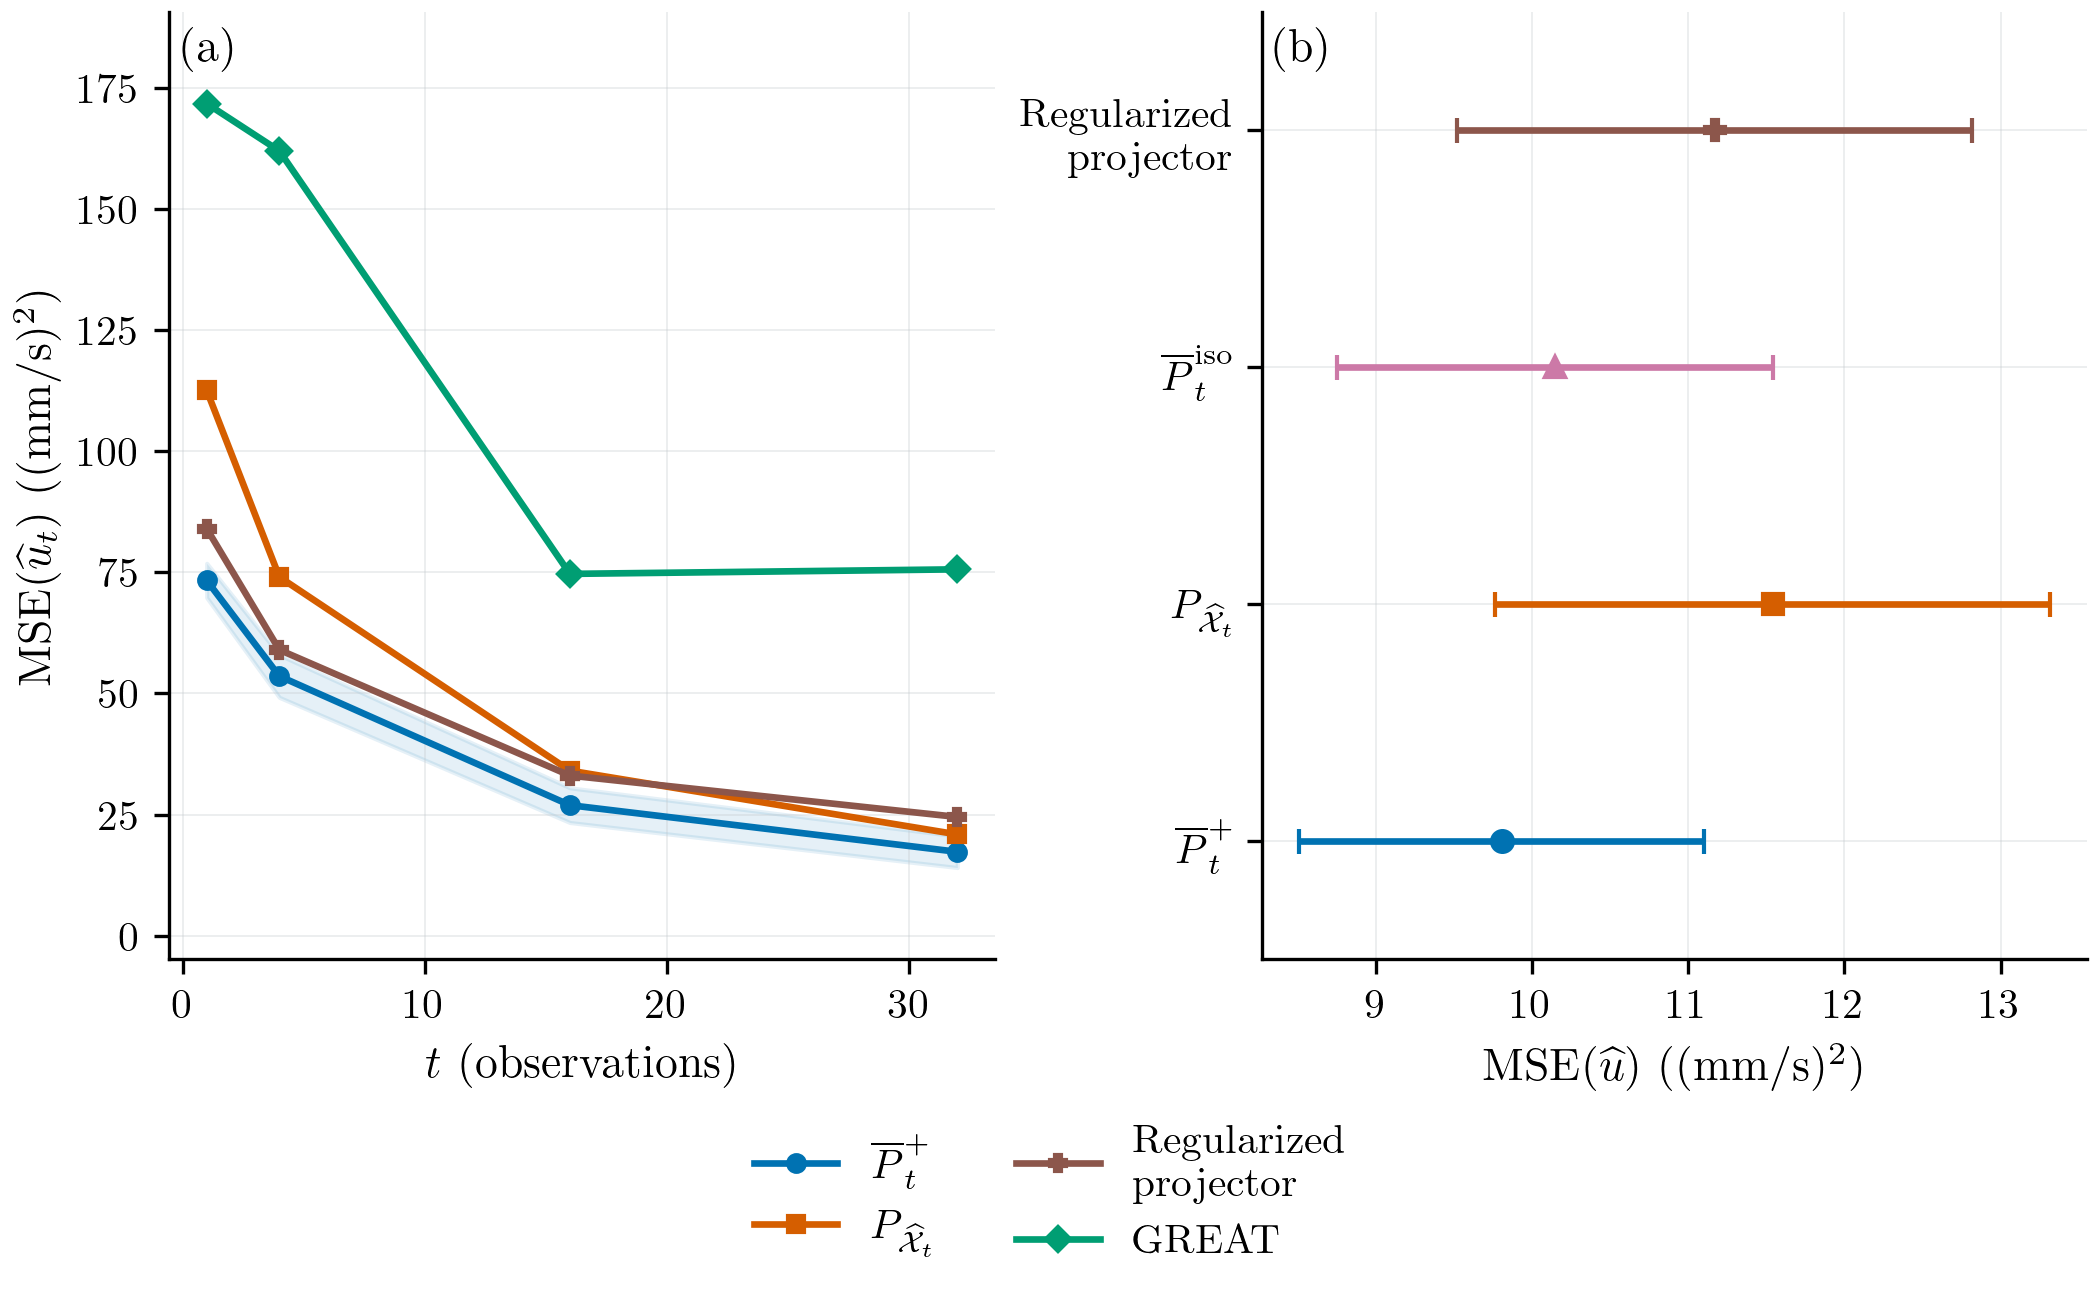

In [5]:
# Edit these controls, the labels below, or any Matplotlib call in this cell.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D

data = load_contact_plot_data(ROOT, 'task_performance', page=1)
DPI = 300
FIGSIZE = (7.0, 4.332)
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'task_performance_page1.pdf'

LABELS = {
    "mean": r"$\overline P_t^+$", "mode": r"$P_{\widehat{\mathcal X}_t}$",
    "iso": r"$\overline P_t^{\mathrm{iso}}$", "isotropic": r"$\overline P_t^{\mathrm{iso}}$",
    "regularized": "Regularized\nprojector", "great_window": "GREAT",
    "known": "True variances", "exact_known": r"True variances, $\beta=1$",
    "known_forgetting": "True variances, forgetting",
    "misspecified": "Fixed variances", "learned": "Learned variances",
}
COLORS = {"mean":"#0072B2", "mode":"#D55E00", "iso":"#CC79A7", "isotropic":"#CC79A7",
          "regularized":"#8C564B", "great_window":"#009E73", "known":"#111111",
          "exact_known":"#111111", "known_forgetting":"#8172B2",
          "misspecified":"#999999", "learned":"#0072B2"}
MARKERS = {"mean":"o", "mode":"s", "iso":"^", "isotropic":"^", "regularized":"P",
           "great_window":"D", "known":"s", "exact_known":"s", "known_forgetting":"D",
           "misspecified":"^", "learned":"o"}

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, dpi=DPI, layout="constrained")
for curve in data["curves"]:
    method, points = curve["method"], curve["points"]
    axes[0].plot(points[:,0], points[:,1], marker=MARKERS[method], color=COLORS[method], label=LABELS[method])
    if method == "mean":
        axes[0].fill_between(points[:,0], points[:,2], points[:,3], color=COLORS[method], alpha=.10)
axes[0].set_xlabel(r"$t$ (observations)")
axes[0].set_ylabel(r"$\mathrm{MSE}(\widehat u_t)$ $((\mathrm{mm}/\mathrm{s})^2)$")
axes[0].margins(y=.12)
for row, point in enumerate(data["absolute"], 1):
    method = point["method"]
    axes[1].errorbar(point["mean"], row,
        xerr=[[point["mean"]-point["lower"]], [point["upper"]-point["mean"]]],
        fmt=MARKERS[method], color=COLORS[method], capsize=3., markersize=5.)
axes[1].set(yticks=np.arange(1,len(data["absolute"])+1),
    yticklabels=[LABELS[point["method"]] for point in data["absolute"]],
    ylim=(.5,len(data["absolute"])+.5),
    xlabel=r"$\mathrm{MSE}(\widehat u)$ $((\mathrm{mm}/\mathrm{s})^2)$")
for ax, label in zip(axes, ["(a)", "(b)"]):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#BFC4C8", alpha=.30, linewidth=.45)
    ax.text(.015,.985,label,transform=ax.transAxes,ha="left",va="top")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False, fontsize=10.)

# Custom notebook exports never overwrite the frozen paper catalogue.
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
plt.show()


Panel (a) uses stationary concentrated inputs. Panel (b) reports absolute episode-average $\mathrm{MSE}(\widehat u)$ for the moving sphere condition: every method, including $\overline P_t^+$, has a pointwise 95% interval across the same 256 independent episodes. MSE is the squared error relative to the clean response $P_{\mathcal X_t}v_t$, averaged within each episode, and is displayed in $(\mathrm{mm}/\mathrm{s})^2$. The supplementary second page shows $\mathrm{MSE}_{\mathrm{ref}}-\mathrm{MSE}_{\mathrm B}$ on paired episodes. This is an absolute difference in squared velocity units, rather than a ratio or relative MSE. The mean's self-difference is exactly zero, which explains its absence from the old difference panel. Intervals of absolute means do not replace paired comparisons.

The table reports reference loss minus posterior-mean loss on the concentrated-input stationary checkpoint $t=16$ and the full sphere episode. Positive values favor the posterior mean; brackets are paired pointwise 95% Student intervals in $(\mathrm{mm}/\mathrm{s})^2$. Across these eight fixed comparisons, 8 intervals lie above zero, 0 lie below zero, and 0 include zero. Resolved pairs are shown relative to scheduled independent episodes. These cells are displayed together, including losses and uncertain differences; this count is descriptive and has no simultaneous-coverage guarantee.

| Condition | Reference | Paired gain [95% CI] | Resolved pairs |
| --- | --- | --- | --- |
| Concentrated, $t=16$ | $P_{\widehat{\mathcal X}_t}$ | 7.12 [4.33, 9.91] | 256/256 |
| Concentrated, $t=16$ | $\overline P_t^{\mathrm{iso}}$ | 1.37 [0.728, 2.02] | 256/256 |
| Concentrated, $t=16$ | Regularized projector | 6.11 [4.82, 7.4] | 256/256 |
| Concentrated, $t=16$ | GREAT | 47.7 [40.1, 55.4] | 256/256 |
| Sphere episode | $P_{\widehat{\mathcal X}_t}$ | 1.73 [1.22, 2.25] | 256/256 |
| Sphere episode | $\overline P_t^{\mathrm{iso}}$ | 0.343 [0.226, 0.459] | 256/256 |
| Sphere episode | Regularized projector | 1.36 [0.964, 1.76] | 256/256 |
| Sphere episode | GREAT | 57.8 [50.2, 65.3] | 256/256 |

A benefit over the mode can arise from shrinkage. A benefit over the matched isotropic control supports the value of directional posterior moments for that task and cohort. The latter comparison is the direct anisotropy test. A GREAT comparison also changes the estimator and, in contact, the available input information.

The full grid also retains the plane episode-average isotropic-minus-full gain, 0.00176 [-0.00142, 0.00494], and the final sphere checkpoint gain, -0.00467 [-0.0054, -0.00394], in $(\mathrm{mm}/\mathrm{s})^2$. These fixed checks show why an episode-average gain should not be interpreted as uniform superiority at every time and input condition.

## 4. Which uncertainty matters for the decision

For a fixed query, the posterior squared response risk is
\[
\mathbb E[\|P_{\mathcal X_t}v-\overline P_t^+v\|^2\mid u_{1:t}]
=v^H[\overline P_t^+-(\overline P_t^+)^2]v.
\]
Under the full belief, using another action $\overline P_t^{\mathrm{iso}}v$ adds exactly $\|(\overline P_t^+-\overline P_t^{\mathrm{iso}})v\|^2$ to this expected response error. This is model-based optimality; paired test episodes determine whether it yields a practical advantage under the data-generating process. The matched isotropic control has the same mode and mean squared chordal distance, but can change directional risk and the task action. A fixed-radius 3D sphere encodes density by color under one shared logarithmic normalization. The continuous blue--purple--pink--yellow gradient changes only the color assigned to a density value; saved coordinates, camera, density values and angular widths are retained. Colors do not denote probability-mass quantiles. Gray curves are visible coordinate great circles that help locate directions on the sphere; they are not density contours or credible regions. Contact normals use true antipodal real-line densities. The complex-array sphere is a real-coefficient density section at the original $n=t=64$ checkpoint: it is not a physical far-field radiation pattern, a full posterior, or a normalized sphere marginal. The setup figure shows the physical array response. No estimator or benchmark parameters have changed. Mode, radius and mean overlap do not determine directional response risk. Visible anisotropy does not itself prove a repeated-experiment task advantage. PDFs retain vector LaTeX text and curves; all current preview and raster layers are 300 dpi. The font sizes, line widths and figure layout follow the implementation-notebook protocol. Inline images are scaled for reading; the full-resolution PNG and PDF links preserve the export resolution. In the contact risk panel, $v(\theta)=\cos\theta\,e_2+\sin\theta\,e_3$ is a unit query and $\theta$ is measured in radians. The vertical axis is $v(\theta)^\top[\overline P-(\overline P)^2]v(\theta)$, where $\overline P$ denotes the full $\overline P_t^+$ or the matched $\overline P_t^{\mathrm{iso}}$ indicated in the legend. Each curve uses its own belief and its own mean; they are not two algorithms' errors against a common truth. The visible orange marker identifies the common modal normal; its antipode is the same contact plane. The constructed equal-distance-law counterexample is a separately identified supplementary page.

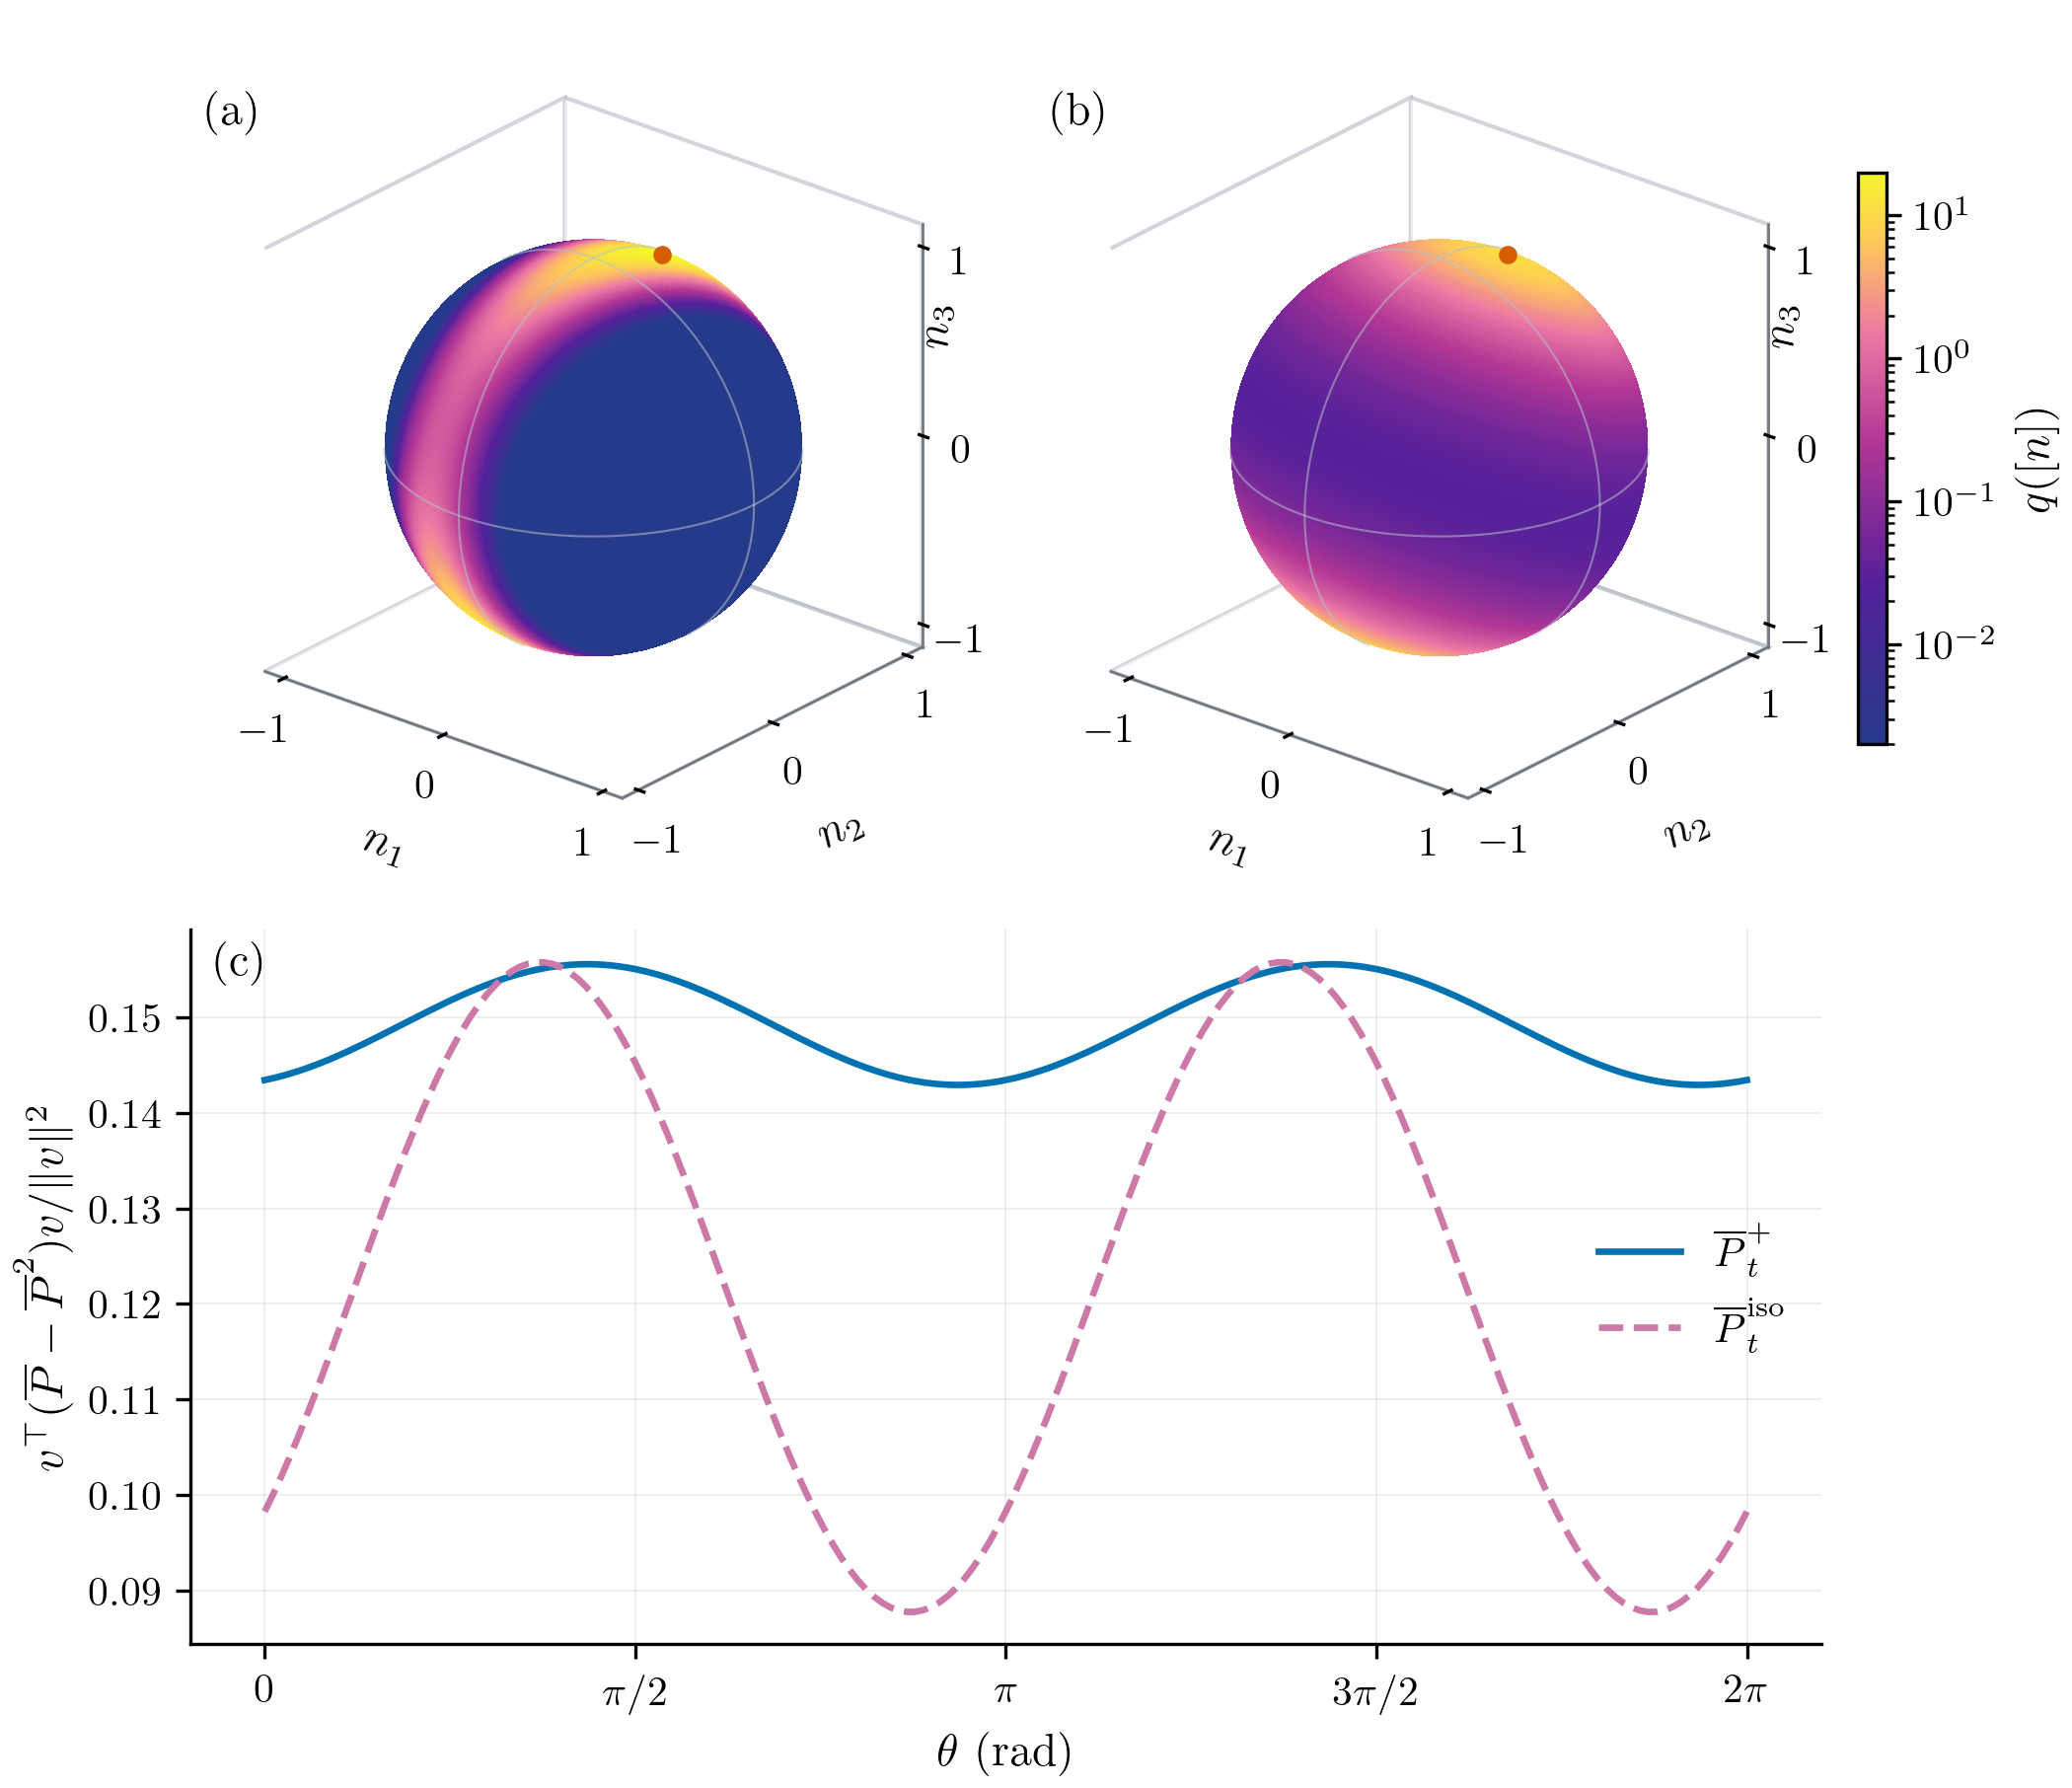

In [6]:
# Edit these controls, the labels below, or any Matplotlib call in this cell.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D

data = load_contact_plot_data(ROOT, 'posterior_anisotropy', page=1)
DPI = 300
FIGSIZE = (7.0, 6.042)
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'posterior_anisotropy_page1.pdf'

LABELS = {
    "mean": r"$\overline P_t^+$", "mode": r"$P_{\widehat{\mathcal X}_t}$",
    "iso": r"$\overline P_t^{\mathrm{iso}}$", "isotropic": r"$\overline P_t^{\mathrm{iso}}$",
    "regularized": "Regularized\nprojector", "great_window": "GREAT",
    "known": "True variances", "exact_known": r"True variances, $\beta=1$",
    "known_forgetting": "True variances, forgetting",
    "misspecified": "Fixed variances", "learned": "Learned variances",
}
COLORS = {"mean":"#0072B2", "mode":"#D55E00", "iso":"#CC79A7", "isotropic":"#CC79A7",
          "regularized":"#8C564B", "great_window":"#009E73", "known":"#111111",
          "exact_known":"#111111", "known_forgetting":"#8172B2",
          "misspecified":"#999999", "learned":"#0072B2"}
MARKERS = {"mean":"o", "mode":"s", "iso":"^", "isotropic":"^", "regularized":"P",
           "great_window":"D", "known":"s", "exact_known":"s", "known_forgetting":"D",
           "misspecified":"^", "learned":"o"}

# All display choices are local to this cell. The saved density values stay fixed.
ELEVATION, AZIMUTH = 25., -50.
COLOR_DECADES = 4.
DENSITY_COLORS = [(0.,"#263a8b"),(.28,"#55209a"),(.53,"#b33695"),
                  (.72,"#ed78a4"),(.88,"#ffc85a"),(1.,"#f4f52b")]
cmap = colors.LinearSegmentedColormap.from_list("density_blue_pink_yellow", DENSITY_COLORS, N=256)
cmap.set_under(cmap(0.)); cmap.set_over(cmap(1.))
peak = max(float(np.max(values)) for values in data["log_density"])
norm = colors.LogNorm(vmin=np.exp(peak-COLOR_DECADES*np.log(10.)), vmax=np.exp(peak), clip=True)
fig = plt.figure(figsize=FIGSIZE, dpi=DPI, layout="constrained")
grid = fig.add_gridspec(2,2,height_ratios=(1.25,1.))
spheres = [fig.add_subplot(grid[0,index],projection="3d") for index in range(2)]
el, az = np.deg2rad([ELEVATION, AZIMUTH])
facing = np.array([np.cos(el)*np.cos(az), np.cos(el)*np.sin(az), np.sin(el)])
for ax, nodes, log_density, label in zip(spheres,data["nodes"],data["log_density"],["(a)","(b)"]):
    ax.computed_zorder = False
    rgba = cmap(norm(np.exp(log_density)))
    surface = ax.plot_surface(nodes[...,0],nodes[...,1],nodes[...,2],facecolors=rgba,
        shade=False,linewidth=0,antialiased=False,rstride=1,cstride=1,zorder=1)
    surface.set_rasterized(True)
    phi = np.linspace(0.,2*np.pi,241)
    for first, second in [(0,1),(0,2),(1,2)]:
        ring = np.zeros((len(phi),3))
        ring[:,first],ring[:,second] = 1.006*np.cos(phi),1.006*np.sin(phi)
        visible = np.where((ring@facing>=0.)[:,None],ring,np.nan)
        ax.plot(*visible.T,color="#B7C0CB",linewidth=.5,alpha=.55,zorder=3)
    mode = data["mode"]/np.linalg.norm(data["mode"])
    visible_mode = mode if mode@facing>=0. else -mode
    ax.scatter(*visible_mode,marker="o",s=12,color="#D55E00",depthshade=False,zorder=4)
    ax.set_proj_type("ortho"); ax.view_init(elev=ELEVATION,azim=AZIMUTH)
    ax.set_box_aspect((1.,1.,1.))
    ax.set(xlim=(-1.12,1.12),ylim=(-1.12,1.12),zlim=(-1.12,1.12),
        xticks=(-1.,0.,1.),yticks=(-1.,0.,1.),zticks=(-1.,0.,1.))
    ax.set_xlabel(r"$n_1$",labelpad=-2);ax.set_ylabel(r"$n_2$",labelpad=-2)
    ax.set_zlabel("")
    ax.text2D(.95,.67,r"$n_3$",transform=ax.transAxes,rotation=90,ha="center",va="center",fontsize=11.)
    ax.tick_params(labelsize=10.,pad=-2,length=1);ax.grid(False)
    for axis in (ax.xaxis,ax.yaxis,ax.zaxis):
        axis.pane.set_facecolor((1.,1.,1.,0.));axis.pane.set_edgecolor((.65,.68,.72,.35))
        axis.line.set_color("#70777D");axis.line.set_linewidth(.65)
    ax.text2D(.02,.97,label,transform=ax.transAxes,ha="left",va="top")
fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),ax=spheres,label=r"$q([n])$",shrink=.64,pad=.015)
ax = fig.add_subplot(grid[1,:])
ax.plot(data["theta"],data["risk_full"],color=COLORS["mean"],label=LABELS["mean"])
ax.plot(data["theta"],data["risk_iso"],"--",color=COLORS["iso"],label=LABELS["iso"])
ax.set_xlabel(r"$\theta$ (rad)")
ax.set_ylabel(r"$v^\top(\overline P-\overline P^2)v/\|v\|^2$")
ax.set(xticks=np.linspace(0.,2*np.pi,5),xticklabels=[r"$0$",r"$\pi/2$",r"$\pi$",r"$3\pi/2$",r"$2\pi$"])
ax.legend(frameon=False,fontsize=10.)
ax.spines[["top","right"]].set_visible(False)
ax.grid(color="#BFC4C8",alpha=.30,linewidth=.45)
ax.text(.015,.985,"(c)",transform=ax.transAxes,ha="left",va="top")

# Custom notebook exports never overwrite the frozen paper catalogue.
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
plt.show()


## 5. Learning variances for future observations

Causal scale fits use completed disjoint past blocks and change future variances only. Each observation is assimilated once. The saved pre-observation predictive score excludes the scored observation from fitting. State, clean-response and noisy-next-observation intervals are distinct targets. Inclusion, widths and proper scores must be read together; integration/quantile precision and frequentist calibration are different checks.

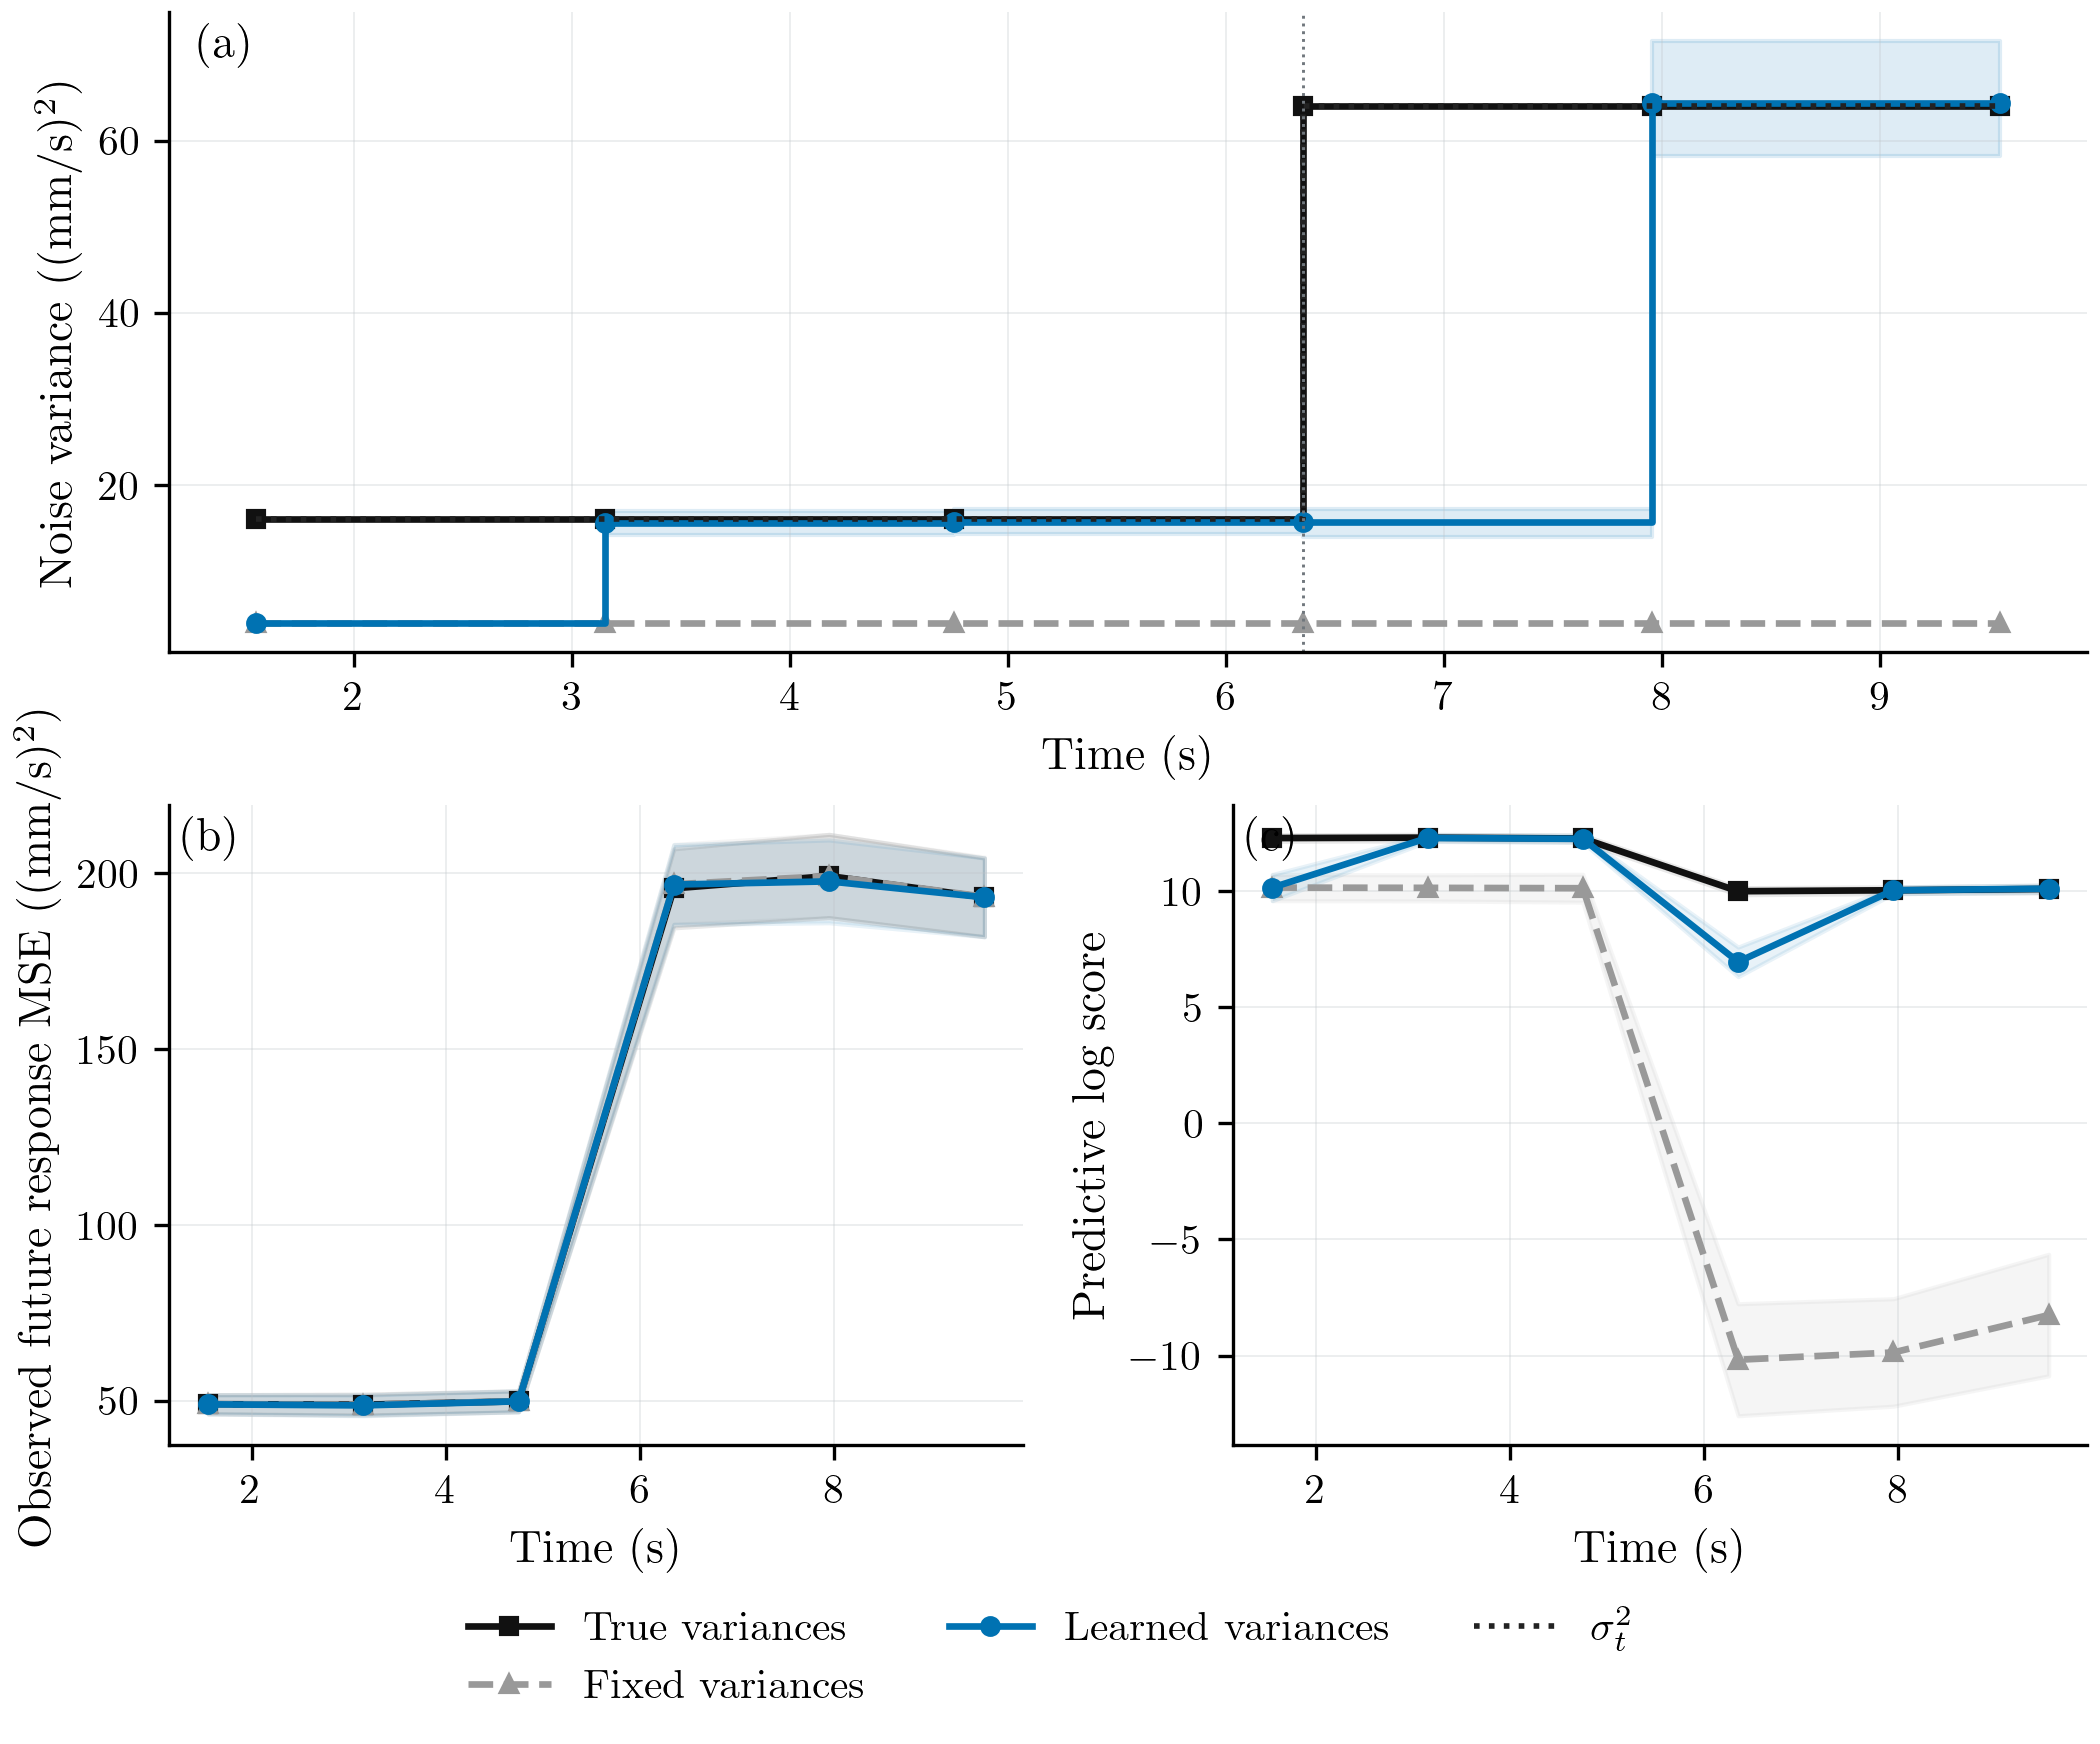

In [7]:
# Edit these controls, the labels below, or any Matplotlib call in this cell.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D

data = load_contact_plot_data(ROOT, 'noise_adaptation', page=1)
DPI = 300
FIGSIZE = (7.0, 5.814)
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'noise_adaptation_page1.pdf'

LABELS = {
    "mean": r"$\overline P_t^+$", "mode": r"$P_{\widehat{\mathcal X}_t}$",
    "iso": r"$\overline P_t^{\mathrm{iso}}$", "isotropic": r"$\overline P_t^{\mathrm{iso}}$",
    "regularized": "Regularized\nprojector", "great_window": "GREAT",
    "known": "True variances", "exact_known": r"True variances, $\beta=1$",
    "known_forgetting": "True variances, forgetting",
    "misspecified": "Fixed variances", "learned": "Learned variances",
}
COLORS = {"mean":"#0072B2", "mode":"#D55E00", "iso":"#CC79A7", "isotropic":"#CC79A7",
          "regularized":"#8C564B", "great_window":"#009E73", "known":"#111111",
          "exact_known":"#111111", "known_forgetting":"#8172B2",
          "misspecified":"#999999", "learned":"#0072B2"}
MARKERS = {"mean":"o", "mode":"s", "iso":"^", "isotropic":"^", "regularized":"P",
           "great_window":"D", "known":"s", "exact_known":"s", "known_forgetting":"D",
           "misspecified":"^", "learned":"o"}

fig = plt.figure(figsize=FIGSIZE,dpi=DPI,layout="constrained")
grid = fig.add_gridspec(2,2)
axes = [fig.add_subplot(grid[0,:]),fig.add_subplot(grid[1,0]),fig.add_subplot(grid[1,1])]
for curve in data["variance"]:
    method = curve["method"]
    axes[0].step(curve["t"],curve["median"],where="post",color=COLORS[method],
        linestyle="--" if method=="misspecified" else "-",marker=MARKERS[method],label=LABELS[method])
    if method=="learned":
        axes[0].fill_between(curve["t"],curve["lower"],curve["upper"],color=COLORS[method],alpha=.13,step="post")
axes[0].step(data["truth_t"],data["truth"],where="post",color="#222222",linestyle=":",linewidth=1.35,label=r"$\sigma_t^2$")
for event in data["events"]:axes[0].axvline(event,color="#70777D",linestyle=":",linewidth=.7)
axes[0].set_xlabel(data["time_label"])
axes[0].set_ylabel(r"Noise variance $((\mathrm{mm}/\mathrm{s})^2)$")
for ax, name in zip(axes[1:], ["future","scores"]):
    for curve in data[name]:
        method, points = curve["method"], curve["points"]
        ax.plot(points[:,0],points[:,1],marker=MARKERS[method],color=COLORS[method],
            linestyle="--" if method=="misspecified" else "-",label=LABELS[method])
        ax.fill_between(points[:,0],points[:,2],points[:,3],color=COLORS[method],alpha=.09)
    ax.set_xlabel(data["time_label"])
axes[1].set_ylabel(r"Observed future response MSE $((\mathrm{mm}/\mathrm{s})^2)$")
axes[2].set_ylabel("Predictive log score")
for ax, label in zip(axes,["(a)","(b)","(c)"]):
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(color="#BFC4C8",alpha=.30,linewidth=.45)
    ax.text(.015,.985,label,transform=ax.transAxes,ha="left",va="top")
handles = {}
for ax in axes:
    for handle,label in zip(*ax.get_legend_handles_labels()):handles.setdefault(label,handle)
fig.legend(list(handles.values()),list(handles),loc="outside lower center",ncol=3,frameon=False,fontsize=10.)

# Custom notebook exports never overwrite the frozen paper catalogue.
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
plt.show()


Across all declared interventions, fixed-minus-learned observed future-task gains are fast sphere: -1.67 [-2.05, -1.29]; noise change: 0.34 [0.118, 0.561]. These are paired pointwise 95% intervals over 256 independent episodes; positive gains favor learning. Contact values are in $(\mathrm{mm}/\mathrm{s})^2$. Observation/query losses are averaged inside each episode. The [paired summaries](../results/contact/tables/paper/prediction/paired.csv) retain every control and endpoint.

A fit changes only future observations and decisions. The shaded variance trajectories show repeated-episode spread, not a posterior distribution of the variance. The supplementary sphere page separately shows an individual pre-observation subspace belief. These displays do not establish calibration of empirical-Bayes scales.

In these fixed intervention comparisons, the intervals lie above zero for noise change; the intervals lie below zero for fast sphere.

## 6. Inclusion is a separate test

These calibration experiments use $n=3$ reliability fixtures with unit queries. For a known unit real query $q$, the clean scalar target is $e_1^T Pq$, the first component of its projected response. The noisy target is $\operatorname{Re}(u_{t,1})$; contact observations are real. State ball/HPD reports target the latent subspace and remain separate from these scalar reports. The scalar widths use these fixture units rather than the physical trajectory velocity scale. The first page checks the matched joint prior-predictive regime at $t=64$; the second shows the predeclared drift diagnostic at the same checkpoint. The appended PDF pages show 95% state-ball chordal radii and scalar interval widths at t=64 across all three regimes; each value is computed per independent episode. Fixed-state inclusion checks and all numerical records remain in the full PDF and summary tables.

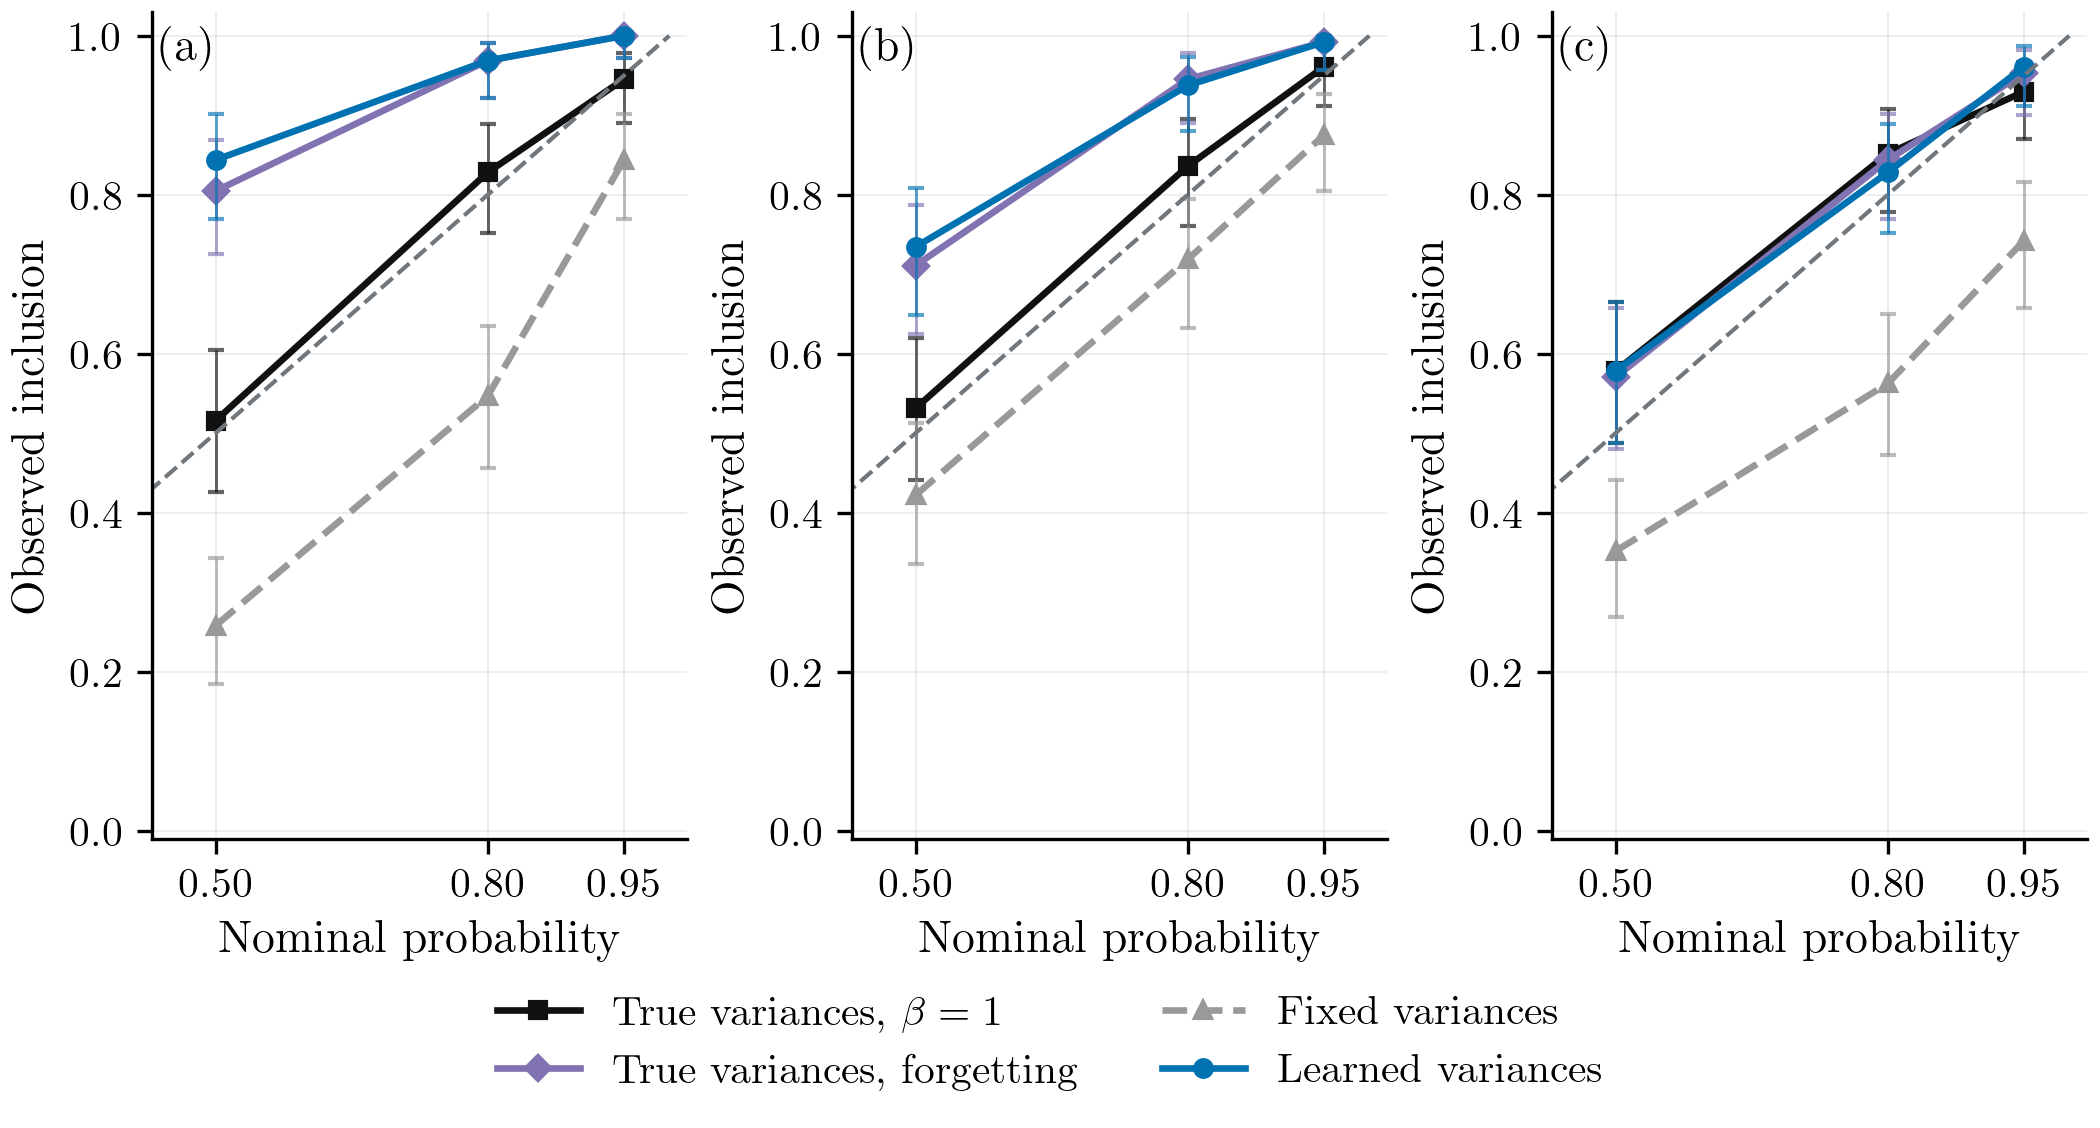

In [8]:
# Edit these controls, the labels below, or any Matplotlib call in this cell.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D

data = load_contact_plot_data(ROOT, 'predictive_calibration', page=2)
DPI = 300
FIGSIZE = (7.0, 3.762)
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'predictive_calibration_page2.pdf'

LABELS = {
    "mean": r"$\overline P_t^+$", "mode": r"$P_{\widehat{\mathcal X}_t}$",
    "iso": r"$\overline P_t^{\mathrm{iso}}$", "isotropic": r"$\overline P_t^{\mathrm{iso}}$",
    "regularized": "Regularized\nprojector", "great_window": "GREAT",
    "known": "True variances", "exact_known": r"True variances, $\beta=1$",
    "known_forgetting": "True variances, forgetting",
    "misspecified": "Fixed variances", "learned": "Learned variances",
}
COLORS = {"mean":"#0072B2", "mode":"#D55E00", "iso":"#CC79A7", "isotropic":"#CC79A7",
          "regularized":"#8C564B", "great_window":"#009E73", "known":"#111111",
          "exact_known":"#111111", "known_forgetting":"#8172B2",
          "misspecified":"#999999", "learned":"#0072B2"}
MARKERS = {"mean":"o", "mode":"s", "iso":"^", "isotropic":"^", "regularized":"P",
           "great_window":"D", "known":"s", "exact_known":"s", "known_forgetting":"D",
           "misspecified":"^", "learned":"o"}

fig, axes = plt.subplots(1,3,figsize=FIGSIZE,dpi=DPI,layout="constrained")
for ax,panel,label in zip(axes,data["panels"],["(a)","(b)","(c)"]):
    for curve in panel["curves"]:
        method,points = curve["method"],curve["points"]
        ax.plot(points[:,0],points[:,1],marker=MARKERS[method],color=COLORS[method],
            linestyle="--" if method=="misspecified" else "-",label=LABELS[method])
        ax.errorbar(points[:,0],points[:,1],yerr=[points[:,1]-points[:,2],points[:,3]-points[:,1]],
            fmt="none",ecolor=COLORS[method],alpha=.65,elinewidth=.7,capsize=2.)
    ax.plot([0.,1.],[0.,1.],"--",color="#70777D",linewidth=1.)
    ax.set(xlim=(.43,1.02),ylim=(-.01,1.03),xticks=[.5,.8,.95])
    ax.set_xlabel("Nominal probability");ax.set_ylabel("Observed inclusion")
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(color="#BFC4C8",alpha=.30,linewidth=.45)
    ax.text(.015,.985,label,transform=ax.transAxes,ha="left",va="top")
fig.legend(*axes[0].get_legend_handles_labels(),loc="outside lower center",ncol=2,frameon=False,fontsize=10.)

# Custom notebook exports never overwrite the frozen paper catalogue.
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
plt.show()


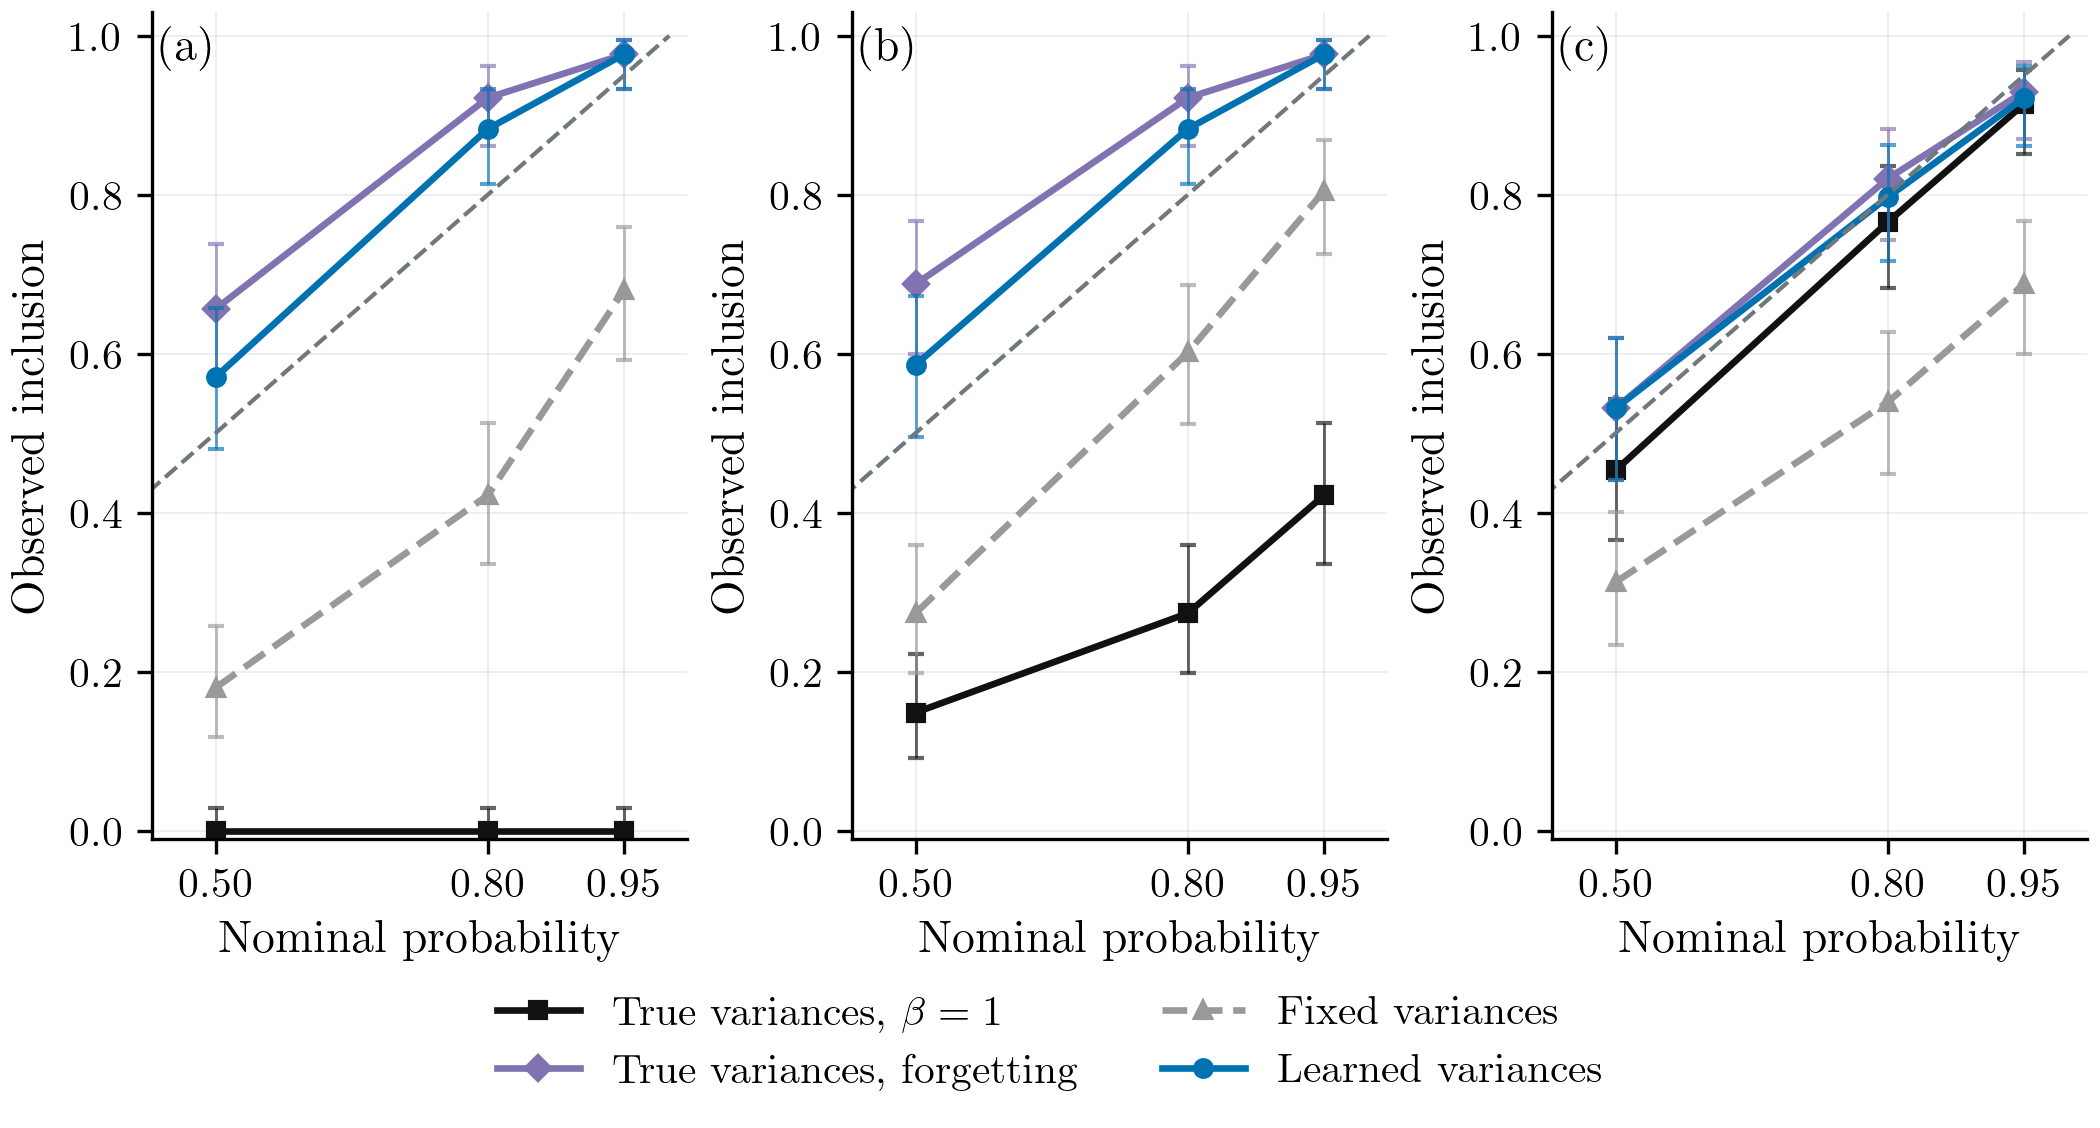

In [9]:
# Edit these controls, the labels below, or any Matplotlib call in this cell.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D

data = load_contact_plot_data(ROOT, 'predictive_calibration', page=6)
DPI = 300
FIGSIZE = (7.0, 3.762)
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'predictive_calibration_page6.pdf'

LABELS = {
    "mean": r"$\overline P_t^+$", "mode": r"$P_{\widehat{\mathcal X}_t}$",
    "iso": r"$\overline P_t^{\mathrm{iso}}$", "isotropic": r"$\overline P_t^{\mathrm{iso}}$",
    "regularized": "Regularized\nprojector", "great_window": "GREAT",
    "known": "True variances", "exact_known": r"True variances, $\beta=1$",
    "known_forgetting": "True variances, forgetting",
    "misspecified": "Fixed variances", "learned": "Learned variances",
}
COLORS = {"mean":"#0072B2", "mode":"#D55E00", "iso":"#CC79A7", "isotropic":"#CC79A7",
          "regularized":"#8C564B", "great_window":"#009E73", "known":"#111111",
          "exact_known":"#111111", "known_forgetting":"#8172B2",
          "misspecified":"#999999", "learned":"#0072B2"}
MARKERS = {"mean":"o", "mode":"s", "iso":"^", "isotropic":"^", "regularized":"P",
           "great_window":"D", "known":"s", "exact_known":"s", "known_forgetting":"D",
           "misspecified":"^", "learned":"o"}

fig, axes = plt.subplots(1,3,figsize=FIGSIZE,dpi=DPI,layout="constrained")
for ax,panel,label in zip(axes,data["panels"],["(a)","(b)","(c)"]):
    for curve in panel["curves"]:
        method,points = curve["method"],curve["points"]
        ax.plot(points[:,0],points[:,1],marker=MARKERS[method],color=COLORS[method],
            linestyle="--" if method=="misspecified" else "-",label=LABELS[method])
        ax.errorbar(points[:,0],points[:,1],yerr=[points[:,1]-points[:,2],points[:,3]-points[:,1]],
            fmt="none",ecolor=COLORS[method],alpha=.65,elinewidth=.7,capsize=2.)
    ax.plot([0.,1.],[0.,1.],"--",color="#70777D",linewidth=1.)
    ax.set(xlim=(.43,1.02),ylim=(-.01,1.03),xticks=[.5,.8,.95])
    ax.set_xlabel("Nominal probability");ax.set_ylabel("Observed inclusion")
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(color="#BFC4C8",alpha=.30,linewidth=.45)
    ax.text(.015,.985,label,transform=ax.transAxes,ha="left",va="top")
fig.legend(*axes[0].get_legend_handles_labels(),loc="outside lower center",ncol=2,frameon=False,fontsize=10.)

# Custom notebook exports never overwrite the frozen paper catalogue.
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
plt.show()


For the matched joint prior-predictive test with true variances, the predeclared $t=64$ 95% reports have inclusion State HPD: 0.945 [0.891, 0.978]; $e_1^T Pq$: 0.961 [0.911, 0.987]; $\operatorname{Re}(u_{t,1})$: 0.93 [0.871, 0.967]. The corresponding learned-variance reports under drift have inclusion State HPD: 0.977 [0.933, 0.995]; $e_1^T Pq$: 0.977 [0.933, 0.995]; $\operatorname{Re}(u_{t,1})$: 0.922 [0.861, 0.962]. Brackets are exact binomial 95% intervals over 128 independent episodes. These drifting intervals do not establish a general coverage guarantee. There are 0 unresolved matched reports and 0 unresolved drifting reports in these cells.

The [calibration summaries](../results/contact/tables/paper/prediction/calibration_summary.csv) also report widths in each target's native units. Numerical tolerance controls how accurately a report is computed; it does not establish repeated-experiment coverage under motion or an incorrect likelihood.

## 7. Computation and the decision to use the framework

The cost plots separate measurement updates, task decisions, uncertainty reports and variance fitting. Each timing on the first PDF page processes exactly 64 observations. Its upper panel includes an update for every observation and computes a task decision at the stated interval. The lower panel separates the nonoverlapping operations for the same 64 observations: optional uncertainty reports and EM fits occur every 32 observations, independently of how often a task decision is computed. Less frequent task decisions still assimilate every observation. Summed medians of individual operations need not equal the median total elapsed time. The second PDF page reports memory, with stored arrays distinguished from tracked allocations. Timings use one predeclared data set and repeated warmed single-thread executions; repetitions of the clock are not additional statistical episodes or worst-case deadlines. Native rank/codimension-one first-moment accuracy does not certify arbitrary-rank moments, floating-point error, second moments or tails.

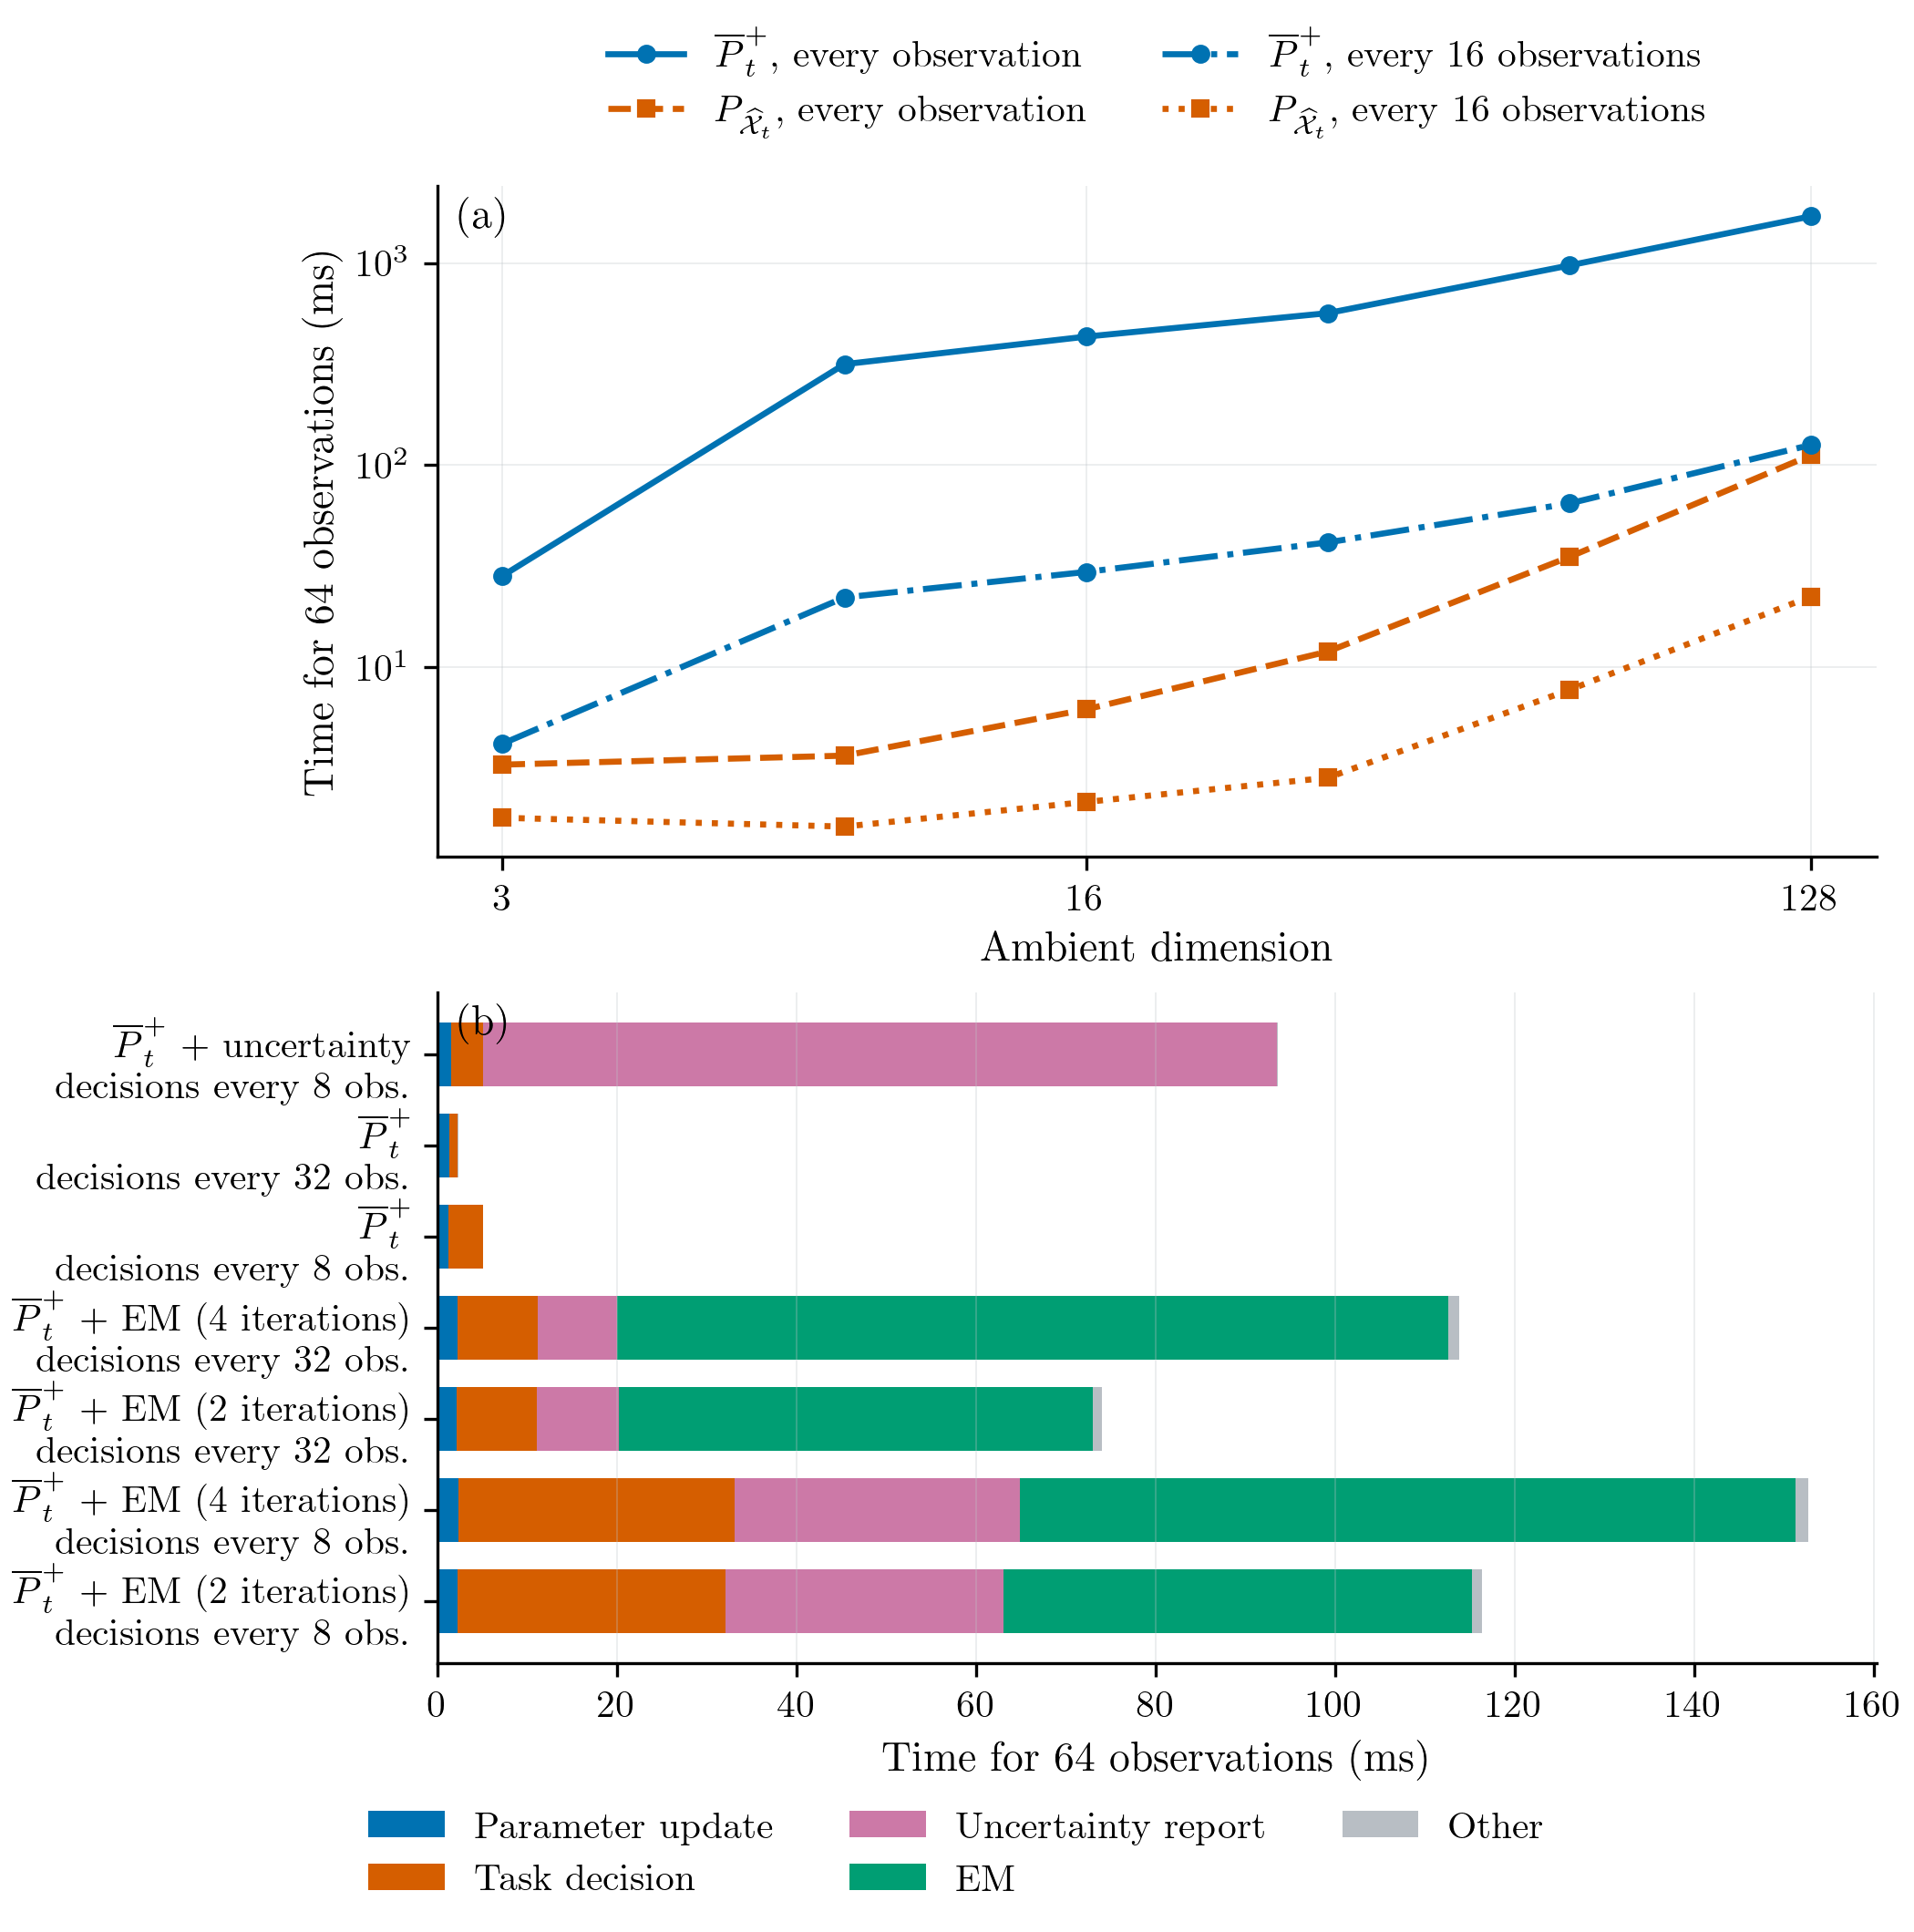

In [10]:
# Edit these controls, the labels below, or any Matplotlib call in this cell.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D

data = load_contact_plot_data(ROOT, 'computation_time', page=1)
DPI = 300
FIGSIZE = (7.0, 7.068)
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'computation_time_page1.pdf'

LABELS = {
    "mean": r"$\overline P_t^+$", "mode": r"$P_{\widehat{\mathcal X}_t}$",
    "iso": r"$\overline P_t^{\mathrm{iso}}$", "isotropic": r"$\overline P_t^{\mathrm{iso}}$",
    "regularized": "Regularized\nprojector", "great_window": "GREAT",
    "known": "True variances", "exact_known": r"True variances, $\beta=1$",
    "known_forgetting": "True variances, forgetting",
    "misspecified": "Fixed variances", "learned": "Learned variances",
}
COLORS = {"mean":"#0072B2", "mode":"#D55E00", "iso":"#CC79A7", "isotropic":"#CC79A7",
          "regularized":"#8C564B", "great_window":"#009E73", "known":"#111111",
          "exact_known":"#111111", "known_forgetting":"#8172B2",
          "misspecified":"#999999", "learned":"#0072B2"}
MARKERS = {"mean":"o", "mode":"s", "iso":"^", "isotropic":"^", "regularized":"P",
           "great_window":"D", "known":"s", "exact_known":"s", "known_forgetting":"D",
           "misspecified":"^", "learned":"o"}

fig = plt.figure(figsize=FIGSIZE,dpi=DPI,layout="constrained")
grid = fig.add_gridspec(2,1)
axes = [fig.add_subplot(grid[0]),fig.add_subplot(grid[1])]
for curve in data["scaling"]:
    method, interval = curve["method"],curve["interval"]
    label=LABELS[method]+(", every observation" if interval==1 else ", every "+str(interval)+" observations")
    axes[0].plot(curve["n"],curve["milliseconds"],marker=MARKERS[method],linestyle=curve["style"],
        color=COLORS[method],label=label)
axes[0].set_xscale("log",base=2);axes[0].set_yscale("log")
axes[0].set_xticks([3,16,128],labels=["3","16","128"])
axes[0].set_yticks([10.,100.,1000.],labels=[r"$10^1$",r"$10^2$",r"$10^3$"])
axes[0].minorticks_off()
axes[0].set_xlabel("Ambient dimension")
axes[0].set_ylabel("Time for 64 observations (ms)")
axes[0].legend(frameon=False,fontsize=10.,ncol=2,loc="lower center",bbox_to_anchor=(.5,1.02))
phase_labels = {"correction":"Parameter update","action":"Task decision","report":"Uncertainty report",
                "fitting":"EM","overhead":"Other"}
phase_colors = {"correction":"#0072B2","action":"#D55E00","report":"#CC79A7",
                "fitting":"#009E73","overhead":"#B8BEC4"}
positions=np.arange(len(data["rows"]))
bottom=np.zeros(len(positions))
for phase in data["phases"]:
    key,values=phase["key"],phase["values"]
    axes[1].barh(positions,values,left=bottom,color=phase_colors[key],height=.7,label=phase_labels[key])
    bottom += values
row_labels=[]
for row in data["rows"]:
    label=LABELS["mean"]
    if row["method"]=="mean_report":label+=" + uncertainty"
    if row["method"]=="adaptive_mean":label+=" + EM ("+str(int(row["em_iterations"]))+" iterations)"
    row_labels.append(label+"\ndecisions every "+str(int(row["action_cadence"]))+" obs.")
axes[1].set(yticks=positions,yticklabels=row_labels)
axes[1].set_xlabel("Time for 64 observations (ms)")
axes[1].set_ylabel("")
for ax,label in zip(axes,["(a)","(b)"]):
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(axis="x" if ax is axes[1] else "both",color="#BFC4C8",alpha=.30,linewidth=.45)
    ax.text(.015,.985,label,transform=ax.transAxes,ha="left",va="top")
fig.legend(*axes[1].get_legend_handles_labels(),loc="outside lower center",ncol=3,frameon=False,fontsize=10.)

# Custom notebook exports never overwrite the frozen paper catalogue.
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
plt.show()


With task decisions every 4 observations and no uncertainty reports, the warmed single-thread times to process 192 observations are GREAT: 75.1 ms (90th percentile 88.1 ms); $\overline P_t^{\mathrm{iso}}$: 25.9 ms (90th percentile 29.2 ms); Posterior mean: 23.1 ms (90th percentile 30.1 ms); $P_{\widehat{\mathcal X}_t}$: 6.58 ms (90th percentile 7.82 ms). Each clock processes 192 observations from the same predeclared task episode; 7 clock repetitions measure execution variability, not independent task-performance episodes. The posterior mean takes 0.308 times the GREAT time, 0.892 times the $\overline P_t^{\mathrm{iso}}$ time, 3.51 times the $P_{\widehat{\mathcal X}_t}$ time. The [cost summaries](../results/contact/tables/paper/computation/summary.csv) include every schedule and phase.

The framework is useful when posterior means improve a consequential decision, directional risk or predictive uncertainty reporting is required, or future variance learning is useful enough to justify its measured cost. A modal or optimized tracking rule remains a sensible choice when only a subspace point is required and that cost dominates. The present results do not support universal superiority, arbitrary-rank scalability, or automatic coverage under mismatch.

## Figure catalogue and provenance

[Main-draft PDFs](../results/main/contact/) and [supplementary PDFs](../results/supplementary/contact/) provide the manuscript page selection. The complete original catalogue is linked below. The paper summary reuses the same evidence and is linked rather than displayed a second time.

- [Setup](../results/contact/setup.pdf)
- [Task performance](../results/contact/task_performance.pdf)
- [Posterior anisotropy](../results/contact/posterior_anisotropy.pdf)
- [Noise adaptation](../results/contact/noise_adaptation.pdf)
- [Information](../results/contact/information.pdf)
- [Posterior curvature](../results/contact/posterior_curvature.pdf)
- [Tracking bound](../results/contact/tracking_bound.pdf)
- [Block updates](../results/contact/block_updates.pdf)
- [Additional comparisons](../results/contact/additional_comparisons.pdf)
- [Variance estimation](../results/contact/variance_estimation.pdf)
- [Predictive calibration](../results/contact/predictive_calibration.pdf)
- [Predictive scores](../results/contact/predictive_scores.pdf)
- [Model mismatch](../results/contact/model_mismatch.pdf)
- [Computation time](../results/contact/computation_time.pdf)
- [Numerical accuracy](../results/contact/numerical_accuracy.pdf)
- [Paper summary](../results/contact/paper_summary.pdf)
- [Supp information tracking](../results/contact/supp_information_tracking.pdf)
- [Supp comparisons](../results/contact/supp_comparisons.pdf)
- [Supp variance prediction cost](../results/contact/supp_variance_prediction_cost.pdf)

The [figure manifest](../results/contact/figure_manifest.json) and [caption notes](../results/contact/caption_notes.md) supply proposed captions, exact selectors, source/data/configuration hashes, seeds, episode and clock repetition counts, numerical budgets, failure status and insertion paths. Historic evidence remains under `archive/a91faab/` and its preserved result paths.